# Mass Balance Modeling for Physical AI

**A hands-on notebook.** You will build mass-balance models from scratch, break them, fix them,
and then use them the way modern Physical AI systems do: as structure inside learned simulators,
as constraints on neural networks, and as the backbone of a robot's digital twin.

| # | Lesson | What you build | Why Physical AI cares |
|---|---|---|---|
| 0 | The one equation | – | Every physical simulator is a bookkeeping system |
| 1 | A single tank | ODE model + budget check | Simplest "world model" with a hard invariant |
| 1b | 🎲 Monte Carlo uncertainty | 4000 tanks at once, overflow risk, sensitivity | Design under uncertainty, domain randomization |
| 2 | Flux form vs. "looks right" | Finite-volume solver | Why learned simulators leak mass |
| 2b | 🎲 Monte Carlo particles | Random-walk transport | Particle simulators conserve mass by counting |
| 3 | Reacting species | Stoichiometric model + conserved moieties | Free supervision you get without knowing the kinetics |
| 3b | 🎲 Gillespie simulation | Exact stochastic chemistry with few molecules | Lab robots, microfluidics, cells |
| 4 | Compartment networks | Matrix model $\dot x = Kx$ | The template for mass-conserving graph models |
| 5 | Learning the dynamics | Black-box vs. structured system ID | Inductive bias beats more parameters |
| 6 | Constraining nonlinear models | Soft loss, hard projection, conserving message passing | PINN-style losses vs. conservation by construction |
| 7 | A robot's digital twin | Kalman filter + spill detector for a pouring robot | Mass balance as a real-time sensor |
| 7b | 🎲 Monte Carlo evaluation | False-alarm rate and delay of the detector | Safety numbers before deployment |
| 7c | 🎲 Particle filter | Sequential Monte Carlo leak detector | Nonlinear, non-Gaussian state estimation |
| 8 | Where this goes next | Map to current research | MC-LSTM, graph network simulators, PINNs, neural ODEs |

Lessons marked 🎲 use **Monte Carlo** methods. They sit next to the deterministic lesson they extend.

**Requirements:** `numpy`, `scipy`, `matplotlib`, and `ipywidgets` for the sliders. No GPU, no deep-learning framework.
Every model is small enough that you can read all of its code.

### How to play with it

* **In the browser:** [open in Google Colab](https://colab.research.google.com/github/dansum/web-apps/blob/main/notebooks/mass-balance-physical-ai/mass_balance_physical_ai.ipynb), then *Runtime → Run all*.
* **On your computer:** `pip install jupyterlab ipywidgets numpy scipy matplotlib`, then `jupyter lab`.
* Cells marked **🎛 Playground** have sliders. Move them and watch the model react.
  Every other cell is plain code: change any number and re-run it with Shift + Enter.

In [ ]:
# In Colab everything is already installed. Elsewhere: pip install numpy scipy matplotlib ipywidgets
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.linalg import null_space, expm
from scipy.optimize import lsq_linear

rng = np.random.default_rng(42)
plt.rcParams.update({
    "figure.figsize": (10, 3.6), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})

# Sliders for the playground cells. Without ipywidgets, the playgrounds run once with default values.
try:
    from ipywidgets import interact, FloatSlider, IntSlider, FloatLogSlider
    HAVE_WIDGETS = True
except ImportError:
    HAVE_WIDGETS = False
    FloatSlider = IntSlider = FloatLogSlider = lambda value, **kw: value

def playground(fn, **sliders):
    if HAVE_WIDGETS:
        for s in sliders.values():
            s.continuous_update = False          # re-run when you release the slider
            s.style = {"description_width": "initial"}
        interact(fn, **sliders)
    else:
        print("ipywidgets not found: showing default values. Install it to get sliders.")
        fn(**sliders)

## Lesson 0 — The one equation

Draw a boundary around anything: a tank, a robot's gripper cup, a battery cell, a warehouse, a grid cell
in a simulator. Call it the **control volume**. Mass inside it can only change in four ways:

$$
\underbrace{\frac{dm}{dt}}_{\text{accumulation}}
= \underbrace{\dot m_{\text{in}}}_{\text{in}} - \underbrace{\dot m_{\text{out}}}_{\text{out}}
+ \underbrace{\dot m_{\text{gen}}}_{\text{generation}} - \underbrace{\dot m_{\text{cons}}}_{\text{consumption}}
$$

For *total* mass, generation and consumption are zero (outside nuclear physics). For a single *species*
(e.g. CO₂, a drug, a pollutant) chemical reactions can create or destroy it.

Three ideas carry the rest of the notebook:

1. **Pick the boundary on purpose.** The same physics gives easy or hard equations depending on the boundary.
2. **Write the model in terms of flows (fluxes) between volumes.** What leaves one volume enters the next.
   Models written this way conserve mass *automatically*, even if the flows are wrong.
3. **The budget must close.** Change in storage = total in − total out. If it does not, either the
   model is broken or something unmeasured is happening (a leak, a spill, a sensor fault). Both are useful to know.

In Physical AI, idea 2 is how you build learned simulators that cannot invent matter,
and idea 3 is how a robot notices it just spilled the coffee.

### Where Monte Carlo fits

Monte Carlo means "answer a question by running a model many times with random numbers and counting the results".
It works hand in hand with mass balances. The mass balance supplies the physics; Monte Carlo handles what is random
or unknown. There are five common combinations, and this notebook covers all of them:

| Monte Carlo use | Question it answers | Lesson |
|---|---|---|
| **Uncertainty propagation** | My inputs are uncertain. How likely is a bad outcome? | 1b |
| **Particle (random-walk) transport** | Can I simulate mass as many moving packets instead of a grid? | 2b |
| **Stochastic kinetics (Gillespie)** | Only a few molecules: what does randomness itself do? | 3b |
| **Monte Carlo evaluation** | How good is my learner or detector on average and in bad cases? | 5, 7b |
| **Sequential Monte Carlo (particle filter)** | How do I track hidden states when the model is nonlinear and beliefs are not bell-shaped? | 7c |

One rule connects them: **randomness goes into the inputs, the events or the beliefs — never into the bookkeeping.**
Every random sample is a full mass-balance model that conserves mass on its own.

## Lesson 1 — A single tank

A tank with cross-section $A$ fills from a pump and drains through a hole at the bottom.
The state is the water mass $m$. The level is $h = m / (\rho A)$.

* Inflow: $q_\text{in}(t)$ (m³/s), set by the pump.
* Outflow (Torricelli's law): $q_\text{out} = C_d\, a \sqrt{2 g h}$.

$$
\frac{dm}{dt} = \rho\,\big(q_\text{in}(t) - C_d\, a\sqrt{2 g h}\big)
$$

The model is nonlinear because of the square root. Setting $dm/dt = 0$ gives the steady-state level
$h^* = \frac{1}{2g}\left(\frac{q_\text{in}}{C_d a}\right)^2$.

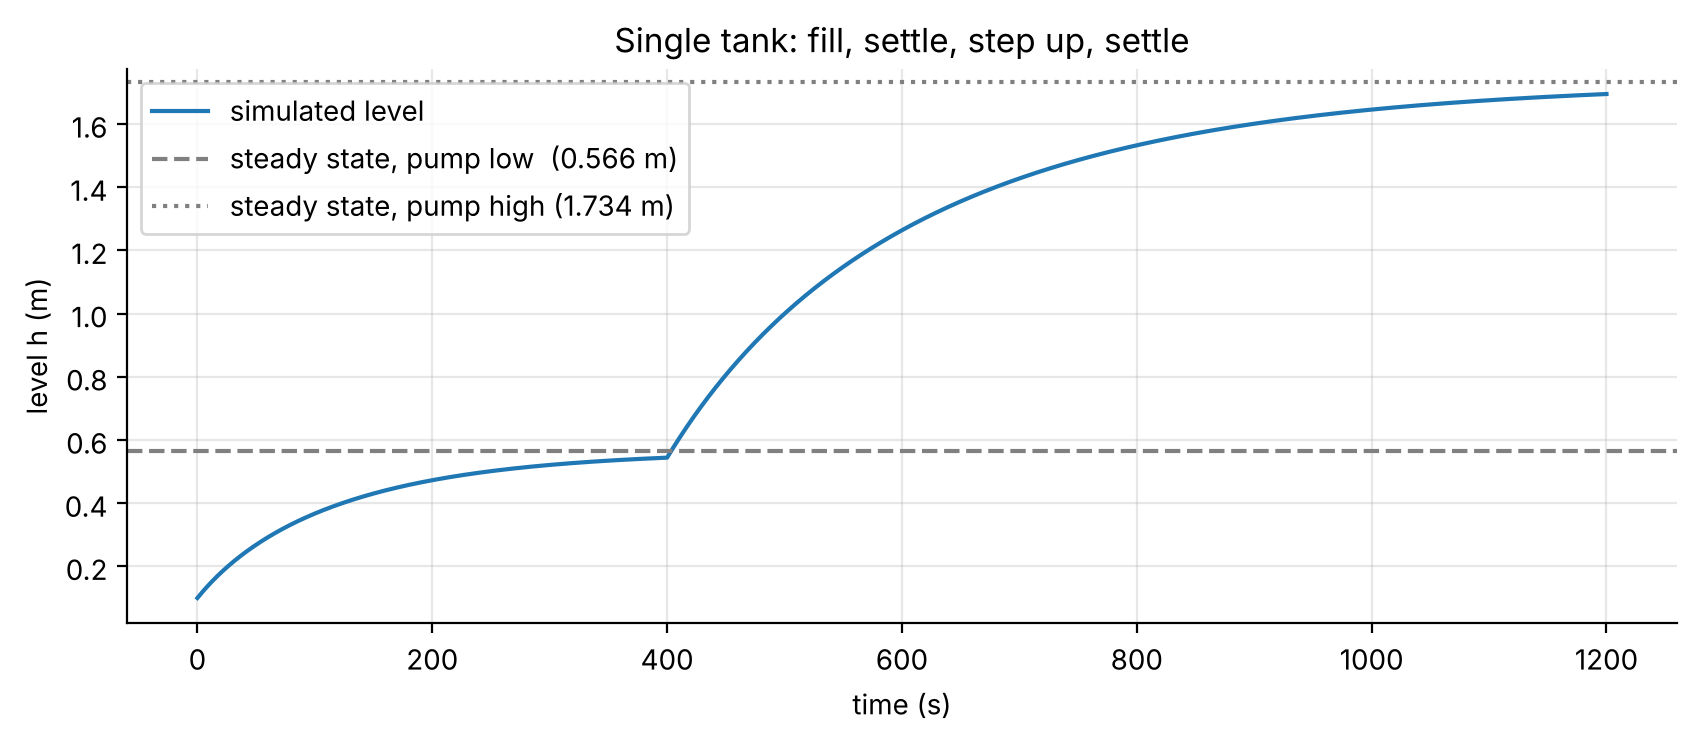

In [2]:
rho, g = 1000.0, 9.81          # kg/m^3, m/s^2
A_tank = 0.05                  # m^2   tank cross-section
a_out, Cd = 2e-4, 0.6          # m^2, -  outlet hole and discharge coefficient

def q_in(t):
    # Pump flow (m^3/s): steps up at t = 400 s.
    return 4e-4 if t < 400 else 7e-4

def q_out(h):
    return Cd * a_out * np.sqrt(2 * g * max(h, 0.0))

def level(m):
    return m / (rho * A_tank)

def tank_rhs(t, y):
    return [rho * (q_in(t) - q_out(level(y[0])))]

t_eval = np.linspace(0, 1200, 2401)
m0 = rho * A_tank * 0.10       # start with 10 cm of water
sol = solve_ivp(tank_rhs, (0, 1200), [m0], t_eval=t_eval, max_step=1.0, rtol=1e-8, atol=1e-8)
h = level(sol.y[0])

h_star = lambda q: (q / (Cd * a_out))**2 / (2 * g)
fig, ax = plt.subplots()
ax.plot(sol.t, h, label="simulated level")
ax.axhline(h_star(4e-4), ls="--", c="gray", label=f"steady state, pump low  ({h_star(4e-4):.3f} m)")
ax.axhline(h_star(7e-4), ls=":",  c="gray", label=f"steady state, pump high ({h_star(7e-4):.3f} m)")
ax.set(xlabel="time (s)", ylabel="level h (m)", title="Single tank: fill, settle, step up, settle")
ax.legend(); plt.show()

### The budget check — your first "unit test" for any simulator

Integrate both sides of the balance from $0$ to $T$:

$$
m(T) - m(0) = \int_0^T \rho\, q_\text{in}\,dt - \int_0^T \rho\, q_\text{out}\,dt
$$

The **closure error** is the left side minus the right side. For a correct model it should be at the level of
numerical error. Get into the habit of computing it for every simulator, including learned ones.

In [3]:
qin_t  = np.array([q_in(t) for t in sol.t])
qout_t = np.array([q_out(hh) for hh in h])
mass_in  = np.trapezoid(rho * qin_t,  sol.t)
mass_out = np.trapezoid(rho * qout_t, sol.t)
storage  = sol.y[0, -1] - sol.y[0, 0]
closure  = storage - (mass_in - mass_out)

print(f"Total in        : {mass_in:9.3f} kg")
print(f"Total out       : {mass_out:9.3f} kg")
print(f"Change in tank  : {storage:9.3f} kg")
print(f"Closure error   : {closure:9.2e} kg  ({abs(closure)/mass_in:.1e} of the inflow)")

Total in        :   720.075 kg
Total out       :   640.240 kg
Change in tank  :    79.760 kg
Closure error   : -7.51e-02 kg  (1.0e-04 of the inflow)


The closure error is tiny and comes only from the trapezoid rule at the pump step.
Keep this number in mind: in Lesson 7 a closure error that is *not* tiny becomes a spill alarm.

### 🎛 Playground 1 — tune the tank

Try: make the hole tiny (the tank takes much longer to settle), or set the pump so high that the steady
level is above the tank's 2 m rim. The closure error should stay tiny whatever you do.

In [ ]:
def play_tank(hole_cm2, discharge_coef, pump_low_L_per_s, pump_high_L_per_s, tank_area_m2):
    a, cd = hole_cm2 * 1e-4, discharge_coef
    ql, qh = pump_low_L_per_s * 1e-3, pump_high_L_per_s * 1e-3
    qin = lambda t: ql if t < 400 else qh
    qout = lambda hh: cd * a * np.sqrt(2 * g * max(hh, 0.0))
    s = solve_ivp(lambda t, y: [(qin(t) - qout(y[0])) / tank_area_m2], (0, 1200), [0.1],
                  t_eval=np.linspace(0, 1200, 1201), max_step=1.0, rtol=1e-8, atol=1e-10)
    hh = s.y[0]
    v_in = np.trapezoid([qin(t) for t in s.t], s.t)
    v_out = np.trapezoid([qout(x) for x in hh], s.t)
    closure = tank_area_m2 * (hh[-1] - hh[0]) - (v_in - v_out)
    fig, ax = plt.subplots()
    ax.plot(s.t, hh, label="level")
    for q, ls in [(ql, "--"), (qh, ":")]:
        ax.axhline((q / (cd * a))**2 / (2 * g), c="gray", ls=ls)
    ax.axhline(2.0, c="C3", lw=1, label="tank rim (2 m)")
    ax.set(xlabel="time (s)", ylabel="level (m)",
           title=f"Closure error: {closure*rho:.2e} kg   (dashed/dotted = steady states)")
    ax.legend(); plt.show()

playground(play_tank,
           hole_cm2=FloatSlider(value=2.0, min=0.5, max=6.0, step=0.1),
           discharge_coef=FloatSlider(value=0.6, min=0.3, max=1.0, step=0.05),
           pump_low_L_per_s=FloatSlider(value=0.4, min=0.0, max=1.5, step=0.05),
           pump_high_L_per_s=FloatSlider(value=0.7, min=0.0, max=1.5, step=0.05),
           tank_area_m2=FloatSlider(value=0.05, min=0.01, max=0.3, step=0.01))

## Lesson 1b — Monte Carlo: how sure is the prediction?

The tank model above used exact numbers: $C_d = 0.6$, a 2 cm² hole, a pump that delivers exactly 0.7 L/s.
In the real world none of these is exact. The discharge coefficient depends on the edge of the hole, the hole
has manufacturing tolerance, and the pump curve drifts with wear.

**Monte Carlo uncertainty propagation** answers "given what I do not know, what can happen?" in four steps:

1. Describe each uncertain input by a probability distribution.
2. Draw many random samples of all inputs together.
3. Run the *same* mass-balance model once per sample.
4. Look at the spread of the outputs: bands, histograms, probabilities of bad events.

Important: Monte Carlo does not replace the mass balance. **Every sample is a complete, physically valid
mass-balance model**, so every sample conserves mass. Only our *knowledge* is uncertain.

The trick that makes it fast is **vectorization**: instead of calling `solve_ivp` 4000 times, we advance all
4000 tanks together with one NumPy array and a fixed-step RK4 integrator.
(We track the level $h$ here; it is just the mass divided by $\rho A$.)

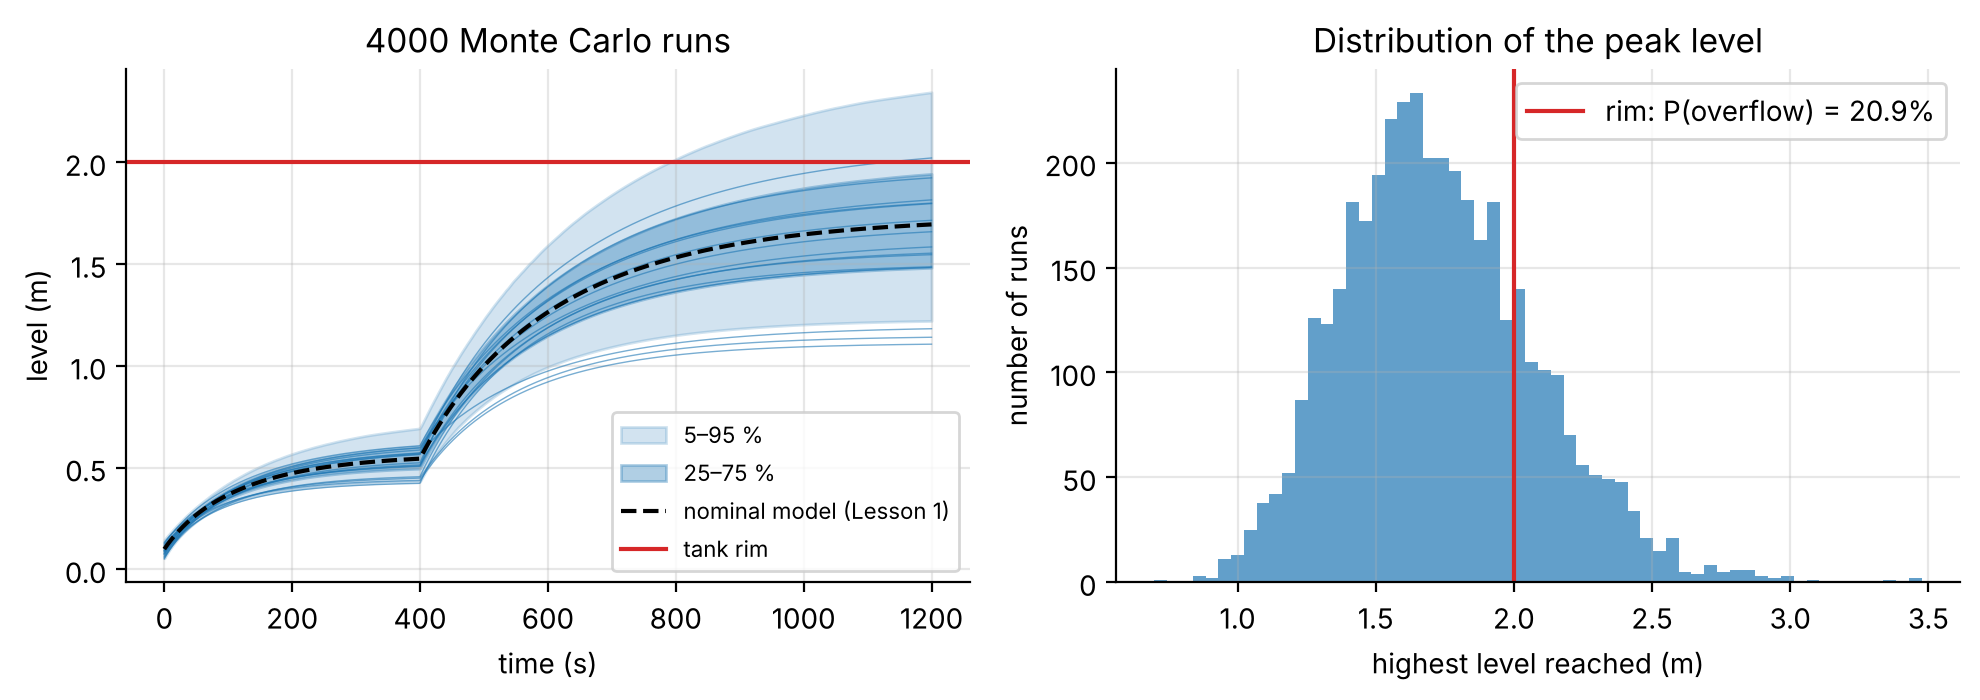

P(overflow) = 0.209 ± 0.013  (95 % confidence, N = 4000)
The nominal model says: peak 1.70 m, so 'no overflow'. Monte Carlo says: about 1 run in 5 overflows.
Largest budget closure error over all runs: 1.9e-04 of the inflow (quadrature error only: every sample conserves mass)


In [5]:
N_mc = 4000
rng_mc = np.random.default_rng(1)
mc_in = {                                                   # uncertain inputs
    "Cd":     rng_mc.normal(0.60, 0.04,   N_mc).clip(0.3, 1.0),  # discharge coefficient (±7 %)
    "a_out":  rng_mc.normal(2e-4, 0.1e-4, N_mc),                  # hole area (±5 % tolerance)
    "q_high": rng_mc.normal(7e-4, 0.5e-4, N_mc),                  # pump flow after the step (±7 %)
    "h0":     rng_mc.uniform(0.05, 0.15,  N_mc),                  # starting level
}

def tank_ensemble(Cd_s, a_s, qh_s, h0_s, q_low=4e-4, area=A_tank, T=1200, dt=1.0):
    # Advance every sample at once with RK4. Returns levels (time x samples) and the relative closure error.
    def rhs(t, hh):
        qin = np.where(t < 400, q_low, qh_s)
        return (qin - Cd_s * a_s * np.sqrt(2 * g * np.maximum(hh, 0))) / area
    n = int(T / dt)
    H = np.empty((n + 1, len(h0_s))); H[0] = h0_s
    hh, v_in, v_out = np.array(h0_s, float), 0.0, 0.0
    for k in range(n):
        t = k * dt
        k1 = rhs(t, hh); k2 = rhs(t + dt/2, hh + dt/2 * k1)
        k3 = rhs(t + dt/2, hh + dt/2 * k2); k4 = rhs(t + dt, hh + dt * k3)
        hh = hh + dt / 6 * (k1 + 2*k2 + 2*k3 + k4)
        H[k + 1] = hh
    # Budget per sample: storage change vs. integrated (in - out), trapezoid rule
    t_grid = np.arange(n + 1) * dt
    qin_g = np.where(t_grid[:, None] < 400, q_low, qh_s[None, :])
    qout_g = Cd_s * a_s * np.sqrt(2 * g * np.maximum(H, 0))
    closure = area * (H[-1] - H[0]) - np.trapezoid(qin_g - qout_g, t_grid, axis=0)
    return H, closure / np.trapezoid(qin_g, t_grid, axis=0)        # relative to the total inflow

H_mc, closure_mc = tank_ensemble(mc_in["Cd"], mc_in["a_out"], mc_in["q_high"], mc_in["h0"])
t_mc = np.arange(H_mc.shape[0]) * 1.0
rim = 2.0
h_max = H_mc.max(axis=0)
overflow = h_max > rim
p_over = overflow.mean()
se_over = np.sqrt(p_over * (1 - p_over) / N_mc)

fig, axs = plt.subplots(1, 2)
pct = np.percentile(H_mc, [5, 25, 50, 75, 95], axis=1)
axs[0].fill_between(t_mc, pct[0], pct[4], color="C0", alpha=0.2, label="5–95 %")
axs[0].fill_between(t_mc, pct[1], pct[3], color="C0", alpha=0.35, label="25–75 %")
axs[0].plot(t_mc, H_mc[:, :15], c="C0", lw=0.5, alpha=0.6)
axs[0].plot(sol.t, h, c="k", ls="--", label="nominal model (Lesson 1)")
axs[0].axhline(rim, c="C3", label="tank rim")
axs[0].set(xlabel="time (s)", ylabel="level (m)", title=f"{N_mc} Monte Carlo runs"); axs[0].legend(fontsize=8)
axs[1].hist(h_max, bins=60, color="C0", alpha=0.7)
axs[1].axvline(rim, c="C3", label=f"rim: P(overflow) = {p_over:.1%}")
axs[1].set(xlabel="highest level reached (m)", ylabel="number of runs", title="Distribution of the peak level")
axs[1].legend(); plt.tight_layout(); plt.show()

print(f"P(overflow) = {p_over:.3f} ± {1.96*se_over:.3f}  (95 % confidence, N = {N_mc})")
print(f"The nominal model says: peak {h.max():.2f} m, so 'no overflow'. Monte Carlo says: about 1 run in {1/p_over:.0f} overflows.")
print(f"Largest budget closure error over all runs: {np.abs(closure_mc).max():.1e} of the inflow"
      " (quadrature error only: every sample conserves mass)")

**Two things to notice.**

* The nominal model is *not* the typical outcome of a nonlinear model. The steady level grows with the *square*
  of $q/(C_d a)$, so small errors in the inputs pile up into a long upper tail. A design that looks safe with
  nominal numbers overflows in about one run out of four or five.
* Each sample closes its own budget. Monte Carlo spreads the *predictions*, not the bookkeeping.

### How many samples do I need? And which input matters most?

A Monte Carlo estimate is itself random. Its standard error shrinks like $1/\sqrt{N}$: four times more samples
halve the error. For a probability $p$ the standard error is $\sqrt{p(1-p)/N}$.

The same samples also give a cheap **sensitivity analysis**: rank-correlate each input with the output.
The input with the largest correlation is the one worth measuring better.

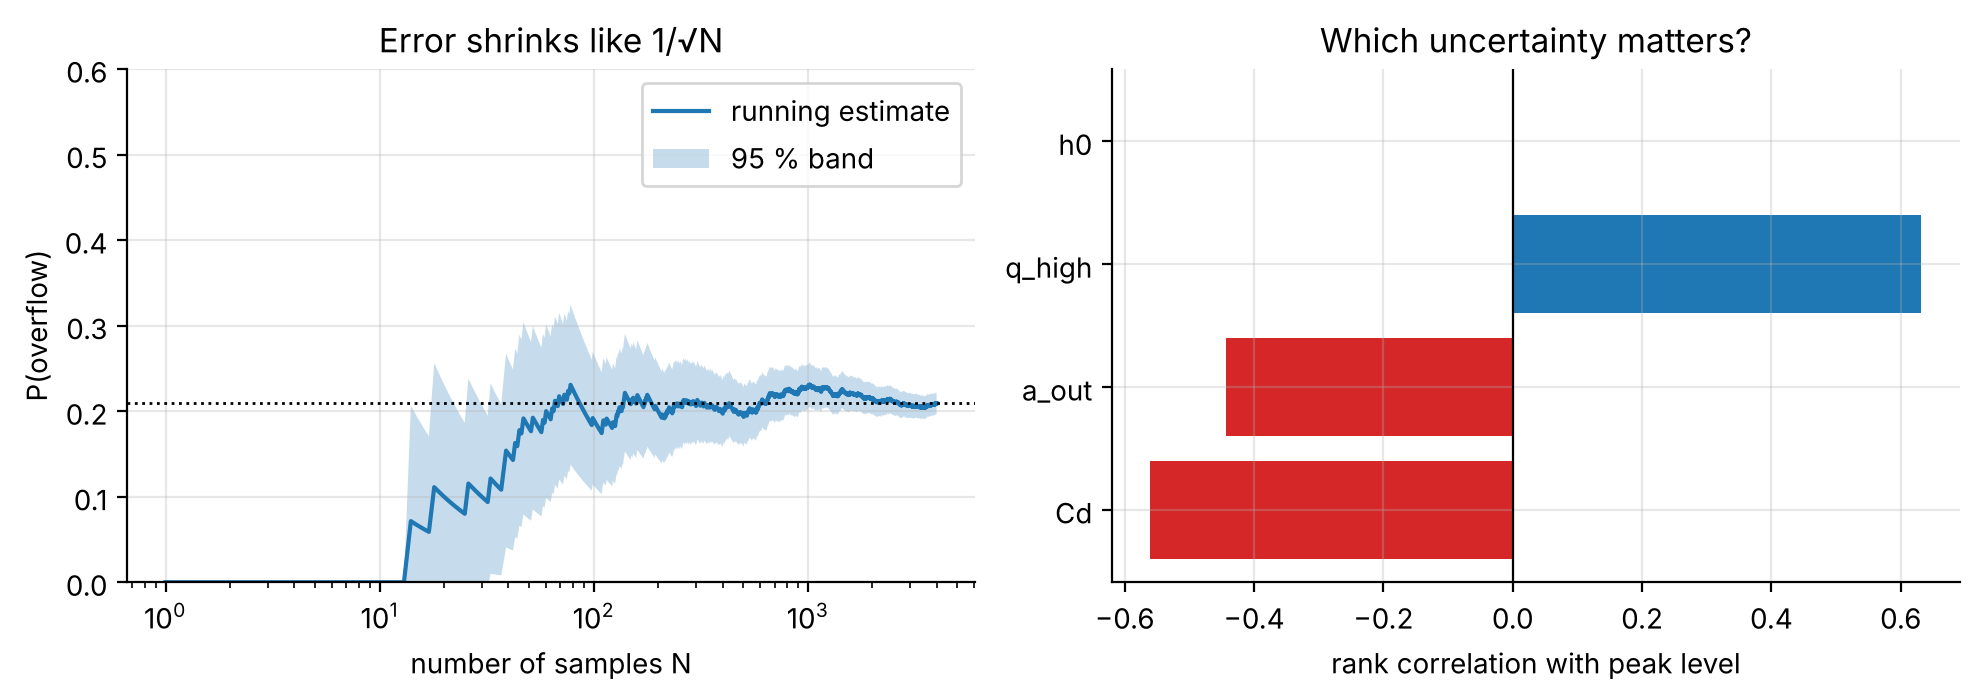

Cd      -0.56
a_out   -0.44
q_high  +0.63
h0      +0.00


In [6]:
from scipy.stats import spearmanr

n_axis = np.arange(1, N_mc + 1)
running_p = np.cumsum(overflow) / n_axis
band = 1.96 * np.sqrt(np.maximum(running_p * (1 - running_p), 1e-12) / n_axis)

fig, axs = plt.subplots(1, 2)
axs[0].semilogx(n_axis, running_p, label="running estimate")
axs[0].fill_between(n_axis, running_p - band, running_p + band, alpha=0.25, label="95 % band")
axs[0].axhline(p_over, c="k", ls=":", lw=1)
axs[0].set(xlabel="number of samples N", ylabel="P(overflow)", title="Error shrinks like 1/√N", ylim=(0, 0.6))
axs[0].legend()
names = ["Cd", "a_out", "q_high", "h0"]
rho_s = [spearmanr(mc_in[n], h_max)[0] for n in names]
axs[1].barh(names, rho_s, color=["C0" if r > 0 else "C3" for r in rho_s])
axs[1].axvline(0, c="k", lw=0.8)
axs[1].set(xlabel="rank correlation with peak level", title="Which uncertainty matters?")
plt.tight_layout(); plt.show()
for n, r in zip(names, rho_s):
    print(f"{n:7s} {r:+.2f}")

The pump flow raises the peak; a larger hole or discharge coefficient lowers it; the starting level hardly matters
(the tank forgets it). To cut the overflow risk, measure the pump and the outlet better, not the starting level.

> **Physical AI link — domain randomization.** Exactly this sampling loop is how robots are trained for the real world.
> Instead of one simulator with nominal physics, a learning agent practices in thousands of simulators whose friction,
> masses, flow coefficients and sensor noise are drawn at random. A policy that works across the whole Monte Carlo
> cloud is far more likely to work on the one real system it has never seen (*sim-to-real transfer*).

### 🎛 Playground 1b — uncertainty budget

Try: set all uncertainties to zero (the histogram collapses to one line); make only the pump uncertain; lower the
number of samples and watch the confidence interval grow.

In [ ]:
def play_mc_tank(Cd_uncert_pct, hole_uncert_pct, pump_uncert_pct, rim_m, n_samples, seed):
    r = np.random.default_rng(seed)
    Cd_s = (0.6 * (1 + Cd_uncert_pct / 100 * r.standard_normal(n_samples))).clip(0.2, 1.0)
    a_s = 2e-4 * (1 + hole_uncert_pct / 100 * r.standard_normal(n_samples)).clip(0.2, None)
    qh_s = (7e-4 * (1 + pump_uncert_pct / 100 * r.standard_normal(n_samples))).clip(0, None)
    H_, _ = tank_ensemble(Cd_s, a_s, qh_s, r.uniform(0.05, 0.15, n_samples))
    hm = H_.max(axis=0); p = (hm > rim_m).mean(); se = np.sqrt(p * (1 - p) / n_samples)
    fig, ax = plt.subplots()
    ax.hist(hm, bins=50, color="C0", alpha=0.7)
    ax.axvline(rim_m, c="C3")
    ax.set(xlabel="highest level reached (m)", ylabel="runs",
           title=f"P(overflow) = {p:.3f} ± {1.96*se:.3f}   ({n_samples} samples)")
    plt.show()

playground(play_mc_tank,
           Cd_uncert_pct=FloatSlider(value=7, min=0, max=20, step=0.5),
           hole_uncert_pct=FloatSlider(value=5, min=0, max=20, step=0.5),
           pump_uncert_pct=FloatSlider(value=7, min=0, max=20, step=0.5),
           rim_m=FloatSlider(value=2.0, min=1.5, max=3.0, step=0.05),
           n_samples=IntSlider(value=2000, min=50, max=10000, step=50),
           seed=IntSlider(value=1, min=0, max=50))

## Lesson 2 — Flux form vs. a model that only *looks* right

Physical AI systems often simulate continua: fluids, sand, crowds, traffic. The workhorse is the
**finite-volume method**: split space into cells and track the mass in each cell.

Take mass per unit length $\rho(x,t)$ moving with a velocity $u(x)$ that changes along the way
(like cars speeding up and slowing down). The true law is the continuity equation:

$$
\frac{\partial \rho}{\partial t} + \frac{\partial (\rho u)}{\partial x} = 0
$$

We will compare two discretizations:

| | Equation used | Discrete update |
|---|---|---|
| **Flux form** | $\partial_t\rho = -\partial_x(\rho u)$ | compute one flux $F_{i+1/2}$ per cell face; subtract it from cell $i$, add it to cell $i{+}1$ |
| **"Advective" form** | $\partial_t\rho = -u\,\partial_x \rho$ | update each cell from its own slope |

The advective form drops the term $-\rho\,\partial_x u$. It looks almost the same, and it is exactly what a
regression model tends to learn when you show it local slopes and ask for the time derivative.

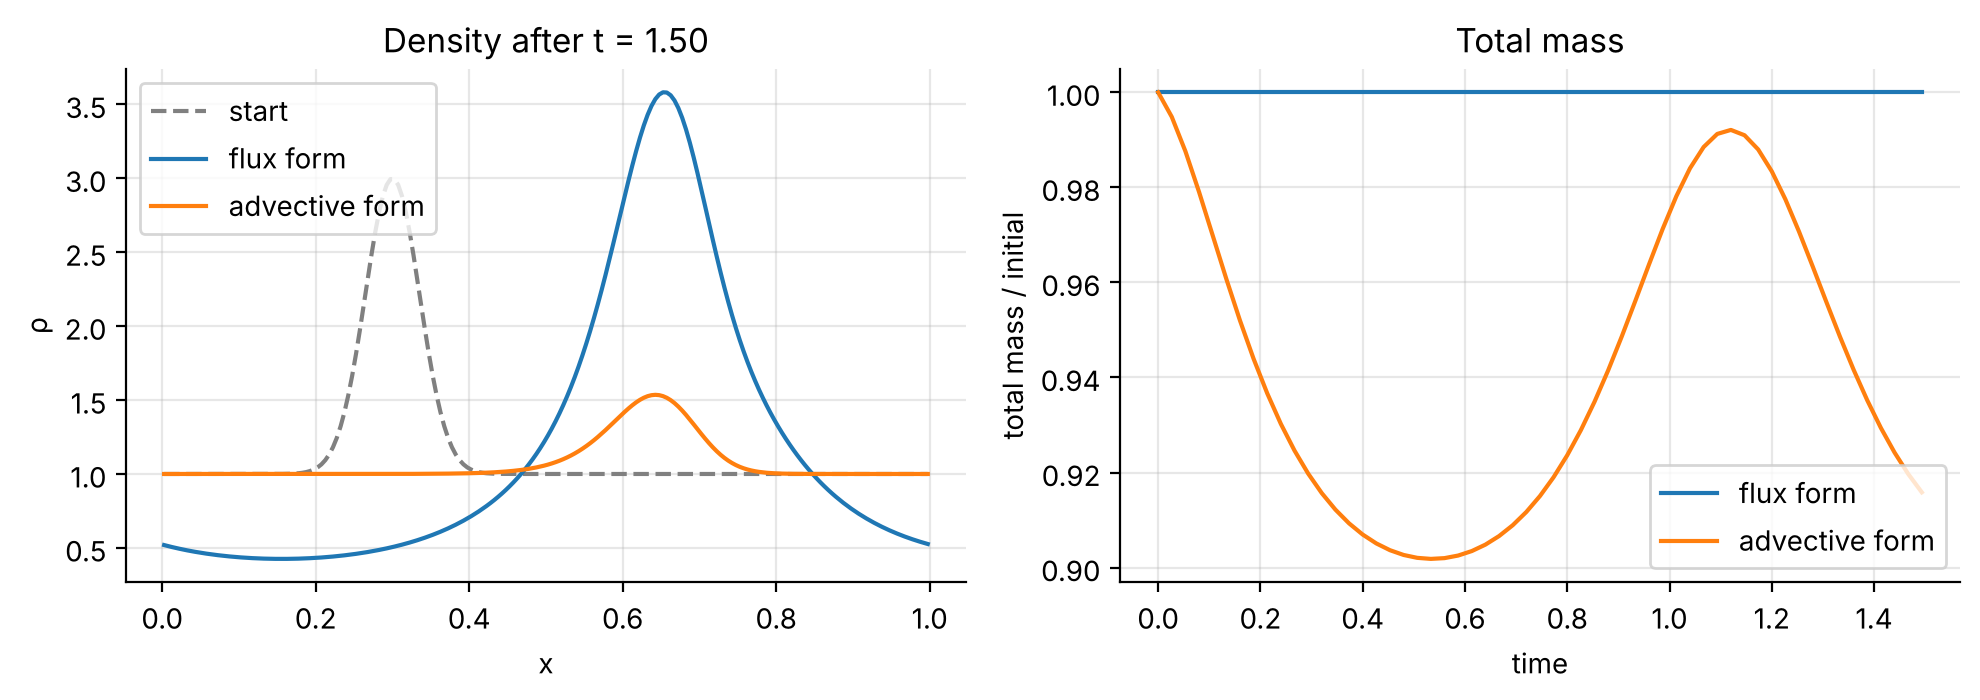

Flux form      : max |mass drift| = 2.2e-16
Advective form : max |mass drift| = 9.8e-02


In [8]:
N, L = 200, 1.0
dx = L / N
xc = (np.arange(N) + 0.5) * dx                        # cell centres
xf = (np.arange(N) + 1.0) * dx                        # right face of each cell
u_cell = 1 + 0.5 * np.sin(2 * np.pi * xc)             # velocity, always > 0
u_face = 1 + 0.5 * np.sin(2 * np.pi * xf)
rho0 = 1.0 + 2.0 * np.exp(-((xc - 0.3) / 0.05)**2)    # background plus a blob

def rhs_flux(r):
    F = u_face * r                                   # upwind flux through the right face (u > 0)
    return -(F - np.roll(F, 1)) / dx                 # out the right face, in from the left face

def rhs_advective(r):
    return -u_cell * (r - np.roll(r, 1)) / dx        # upwind slope, no flux bookkeeping

dt = 0.4 * dx / u_cell.max()                         # CFL-stable time step
n_steps = int(1.5 / dt)
r_f, r_a = rho0.copy(), rho0.copy()
M_f, M_a, times = [], [], []
for n in range(n_steps):
    if n % 20 == 0:
        M_f.append(r_f.sum() * dx); M_a.append(r_a.sum() * dx); times.append(n * dt)
    r_f = r_f + dt * rhs_flux(r_f)                   # plain forward Euler for both
    r_a = r_a + dt * rhs_advective(r_a)

fig, axs = plt.subplots(1, 2)
axs[0].plot(xc, rho0, c="gray", ls="--", label="start")
axs[0].plot(xc, r_f, label="flux form")
axs[0].plot(xc, r_a, label="advective form")
axs[0].set(xlabel="x", ylabel="ρ", title=f"Density after t = {n_steps*dt:.2f}"); axs[0].legend()
axs[1].plot(times, np.array(M_f) / M_f[0], label="flux form")
axs[1].plot(times, np.array(M_a) / M_a[0], label="advective form")
axs[1].set(xlabel="time", ylabel="total mass / initial", title="Total mass"); axs[1].legend()
plt.tight_layout(); plt.show()
print(f"Flux form      : max |mass drift| = {np.max(np.abs(np.array(M_f)/M_f[0]-1)):.1e}")
print(f"Advective form : max |mass drift| = {np.max(np.abs(np.array(M_a)/M_a[0]-1)):.1e}")

**What happened?**

* The flux form conserves mass to round-off (~1e-15) even though forward Euler is a crude integrator
  and the grid is coarse. The reason is *telescoping*: every flux appears twice, once with a minus sign and
  once with a plus sign, so the sum over all cells cancels exactly.
* The advective form creates and destroys mass as the blob passes regions where the flow speeds up or slows down.

> **Rule for Physical AI:** let your model (hand-written or learned) predict **fluxes between cells**, not
> **changes inside cells**. Then conservation does not depend on how accurate the model is. Accuracy and
> conservation become two separate problems, and the hard one is solved for free.

## Lesson 2b — Monte Carlo particles: mass you can count

There is a second, completely different way to simulate the same continuity equation: **chop the mass into many
small packets (particles) and move each one**. Every particle carries the same fixed mass, so the total is simply
(number of particles) × (mass per particle). It cannot change. Conservation is not checked; it is *counted*.

Add mixing (diffusion with coefficient $D$) and the density obeys

$$
\frac{\partial \rho}{\partial t} + \frac{\partial (\rho u)}{\partial x} = D\,\frac{\partial^2 \rho}{\partial x^2}.
$$

The Monte Carlo version: each particle drifts with the flow and takes a random step,

$$
x \leftarrow x + u(x)\,\Delta t + \sqrt{2D\,\Delta t}\;\xi, \qquad \xi \sim \mathcal N(0,1).
$$

The histogram of many such random walkers converges to the solution of the equation above. This is the
*random-walk particle* method used for pollutant plumes, groundwater tracers, and gas or odor plumes that
mobile robots try to trace to their source.

We compare it with the flux-form finite-volume solver from Lesson 2, now with a diffusion flux added.

In [9]:
D_mix = 0.005
dt_rw, T_rw = 1e-3, 1.0

# 1) Finite volume, flux form: advective flux + diffusive flux through each face
def rhs_flux_diffusive(r):
    r_right = np.roll(r, -1)
    F = u_face * 0.5 * (r + r_right) - D_mix * (r_right - r) / dx
    return -(F - np.roll(F, 1)) / dx

r_fv = rho0.copy()
for _ in range(int(T_rw / dt_rw)):
    r_fv = r_fv + dt_rw * rhs_flux_diffusive(r_fv)

# 2) Monte Carlo: sample particles from the initial density, then random-walk them
n_part = 100_000
rng_rw = np.random.default_rng(3)
cdf = np.concatenate([[0.0], np.cumsum(rho0)]); cdf /= cdf[-1]
x_edges = np.linspace(0, L, N + 1)
xp = np.interp(rng_rw.random(n_part), cdf, x_edges)      # inverse-CDF sampling
m_part = rho0.sum() * dx / n_part                          # every particle carries the same mass
u_of = lambda x: 1 + 0.5 * np.sin(2 * np.pi * x)
for _ in range(int(T_rw / dt_rw)):
    xp = (xp + u_of(xp) * dt_rw + np.sqrt(2 * D_mix * dt_rw) * rng_rw.standard_normal(n_part)) % L

def particle_density(xs, mass_each):
    counts, _ = np.histogram(xs, bins=x_edges)
    return counts * mass_each / dx

rho_mc = particle_density(xp, m_part)
print(f"Total mass: start {rho0.sum()*dx:.6f}, finite volume {r_fv.sum()*dx:.6f}, particles {n_part*m_part:.6f}")

Total mass: start 1.177245, finite volume 1.177245, particles 1.177245


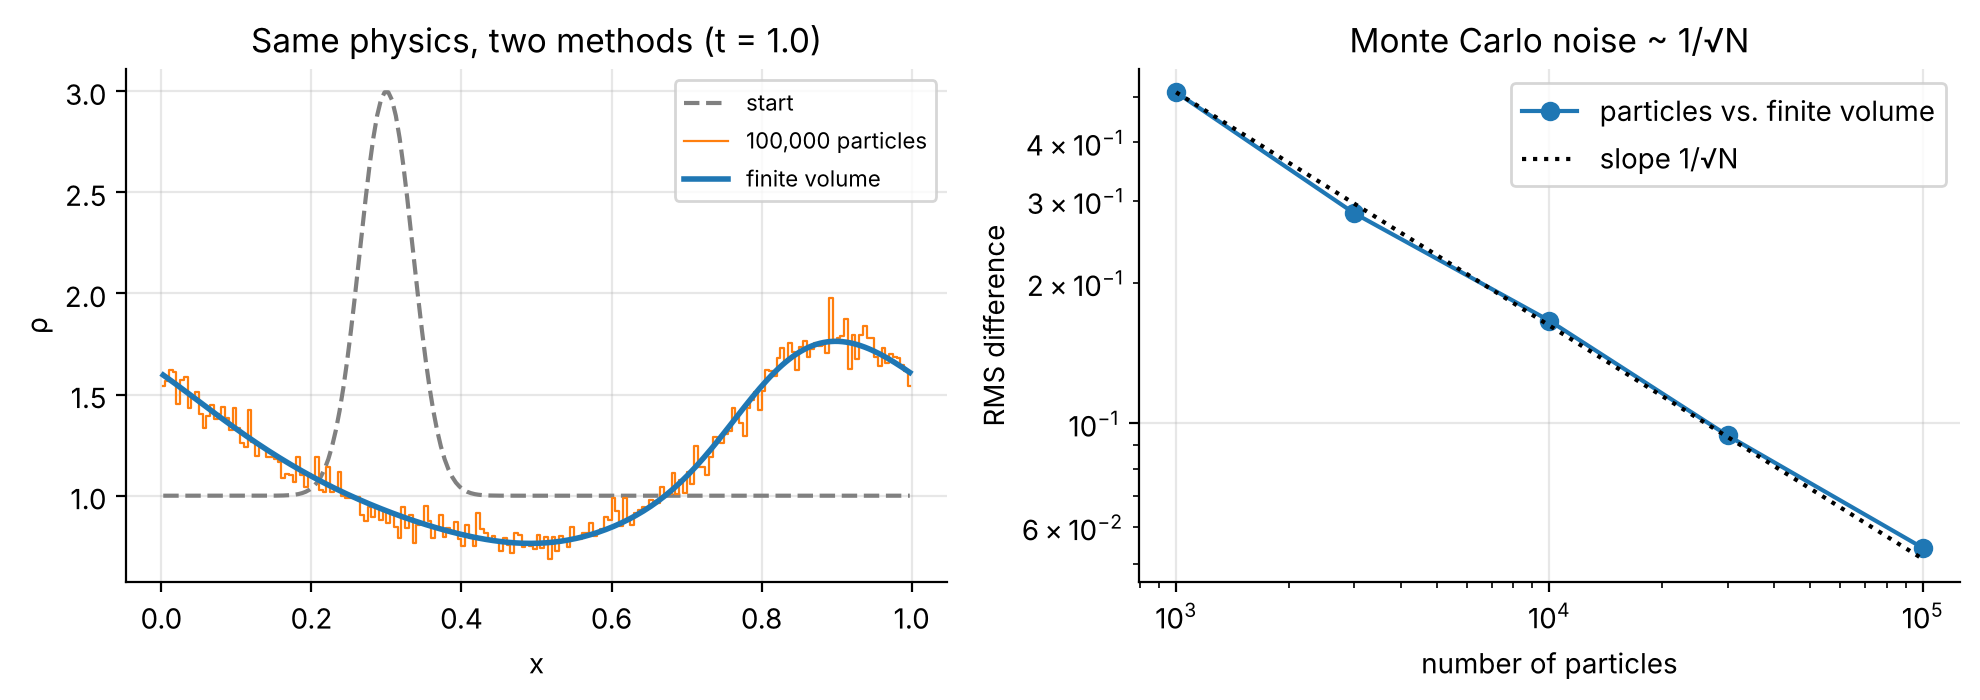

In [10]:
# How does the Monte Carlo noise shrink with more particles?
ns = [1_000, 3_000, 10_000, 30_000, 100_000]
rms = [np.sqrt(np.mean((particle_density(xp[:n], rho0.sum() * dx / n) - r_fv)**2)) for n in ns]

fig, axs = plt.subplots(1, 2)
axs[0].plot(xc, rho0, c="gray", ls="--", label="start")
axs[0].step(xc, rho_mc, where="mid", c="C1", lw=0.8, label=f"{n_part:,} particles")
axs[0].plot(xc, r_fv, c="C0", lw=2, label="finite volume")
axs[0].set(xlabel="x", ylabel="ρ", title=f"Same physics, two methods (t = {T_rw})"); axs[0].legend(fontsize=8)
axs[1].loglog(ns, rms, "o-", label="particles vs. finite volume")
axs[1].loglog(ns, rms[0] * np.sqrt(ns[0] / np.array(ns)), "k:", label="slope 1/√N")
axs[1].set(xlabel="number of particles", ylabel="RMS difference", title="Monte Carlo noise ~ 1/√N"); axs[1].legend()
plt.tight_layout(); plt.show()

| | Finite volume (flux form) | Monte Carlo particles |
|---|---|---|
| Mass conservation | exact, by telescoping fluxes | exact, by counting particles |
| Error | smooth, from the grid | noisy, shrinks like $1/\sqrt{N}$ |
| Complicated geometry, many dimensions | hard (needs a mesh) | easy (just move points) |
| Cost of a small, local quantity | must solve everywhere | only track the particles you need |

Particle thinking is everywhere in Physical AI simulators: smoothed-particle hydrodynamics (SPH), the material point
method (MPM) and position-based fluids all carry mass on particles, so a robot pouring water or scooping sand in
simulation never creates or destroys material. Those methods move particles deterministically; the random walk here
adds the extra ingredient of *diffusion*, which deterministic particles do not give you.

## Lesson 3 — Several species and reactions: conserved quantities for free

Now track several species. Inside the control volume, reactions convert one into another.
Write the reactions as a **stoichiometric matrix** $S$ (rows = species, columns = reactions)
and a vector of reaction rates $r(c)$:

$$
\frac{dc}{dt} = S\, r(c) \quad \text{(closed vessel)}
$$

Example network:

$$
\text{A} + \text{B} \xrightarrow{k_1} \text{C}, \qquad \text{C} \xrightarrow{k_2} \text{A} + \text{D}
$$

**Key trick.** Any row vector $w$ with $w^\top S = 0$ gives a quantity $w^\top c$ that never changes,
*whatever the rate laws are*. These $w$ span the left null space of $S$. Chemists call them conserved
moieties; for us they are invariants we know before we know the kinetics.

In [11]:
species = ["A", "B", "C", "D"]
S = np.array([[-1,  1],     # A
              [-1,  0],     # B
              [ 1, -1],     # C
              [ 0,  1]])    # D
k1, k2 = 2.0, 0.5
def rates(c):
    A, B, C, D = c
    return np.array([k1 * A * B, k2 * C])

W_auto = null_space(S.T).T           # orthonormal basis of the left null space
print("Number of independent conserved quantities:", W_auto.shape[0])

# A readable basis (found by hand from w^T S = 0):
W = np.array([[1, 0, 1, 0],          # "A-moiety": A + C
              [0, 1, 1, 1]])         # "B-moiety": B + C + D
print("Check W @ S = 0:\n", W @ S)
print("Same space as scipy's basis?", np.linalg.matrix_rank(np.vstack([W, W_auto])) == 2)

Number of independent conserved quantities: 2
Check W @ S = 0:
 [[0 0]
 [0 0]]
Same space as scipy's basis? True


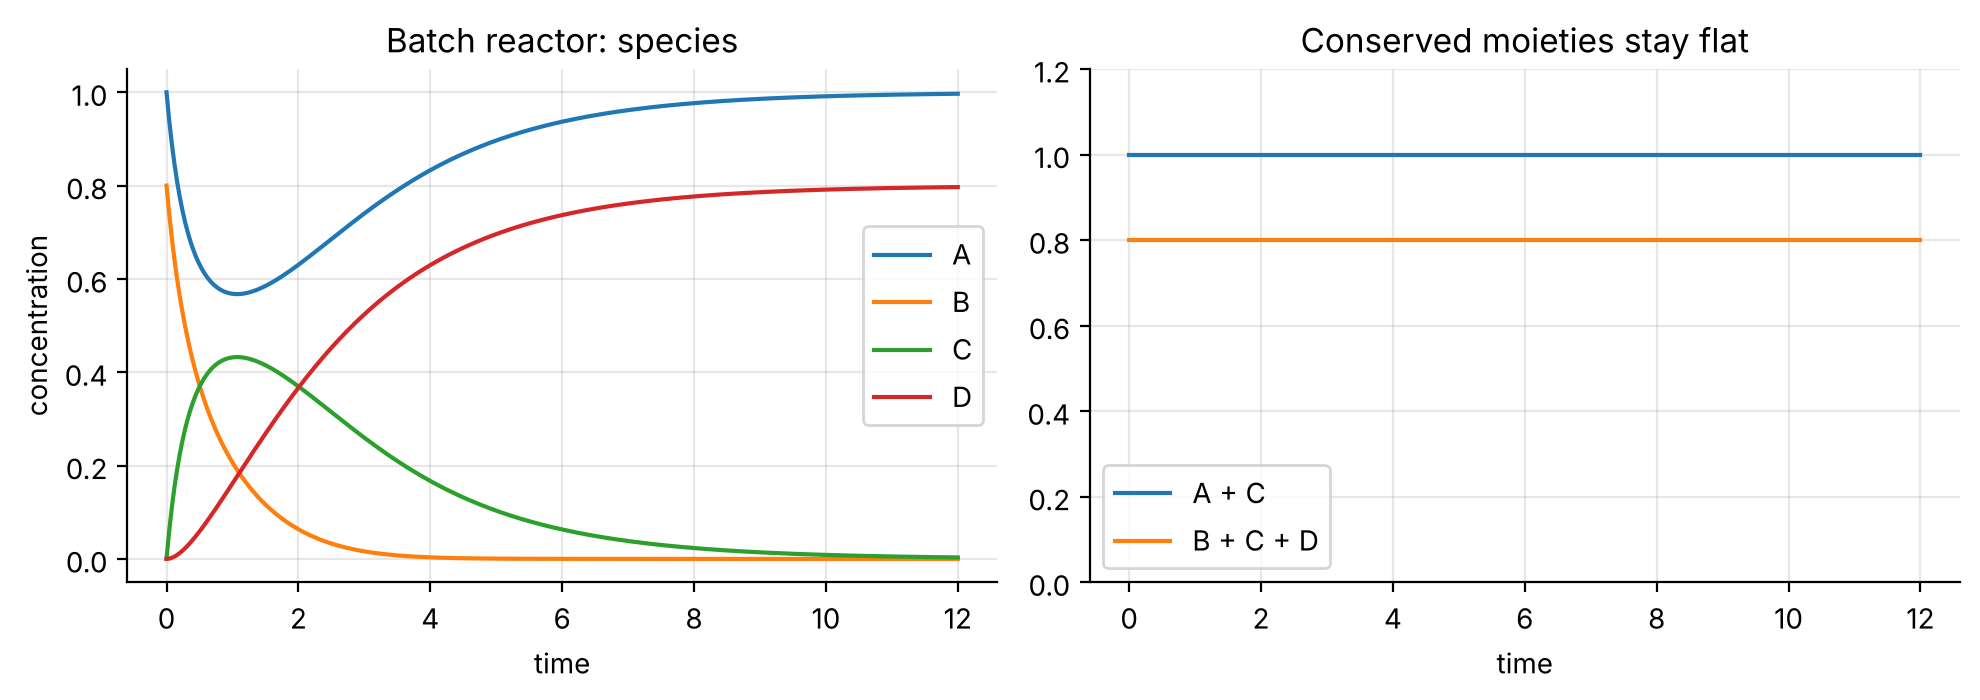

In [12]:
c0 = np.array([1.0, 0.8, 0.0, 0.0])
batch = solve_ivp(lambda t, c: S @ rates(c), (0, 12), c0, t_eval=np.linspace(0, 12, 300), rtol=1e-9)

fig, axs = plt.subplots(1, 2)
for i, s in enumerate(species):
    axs[0].plot(batch.t, batch.y[i], label=s)
axs[0].set(xlabel="time", ylabel="concentration", title="Batch reactor: species"); axs[0].legend()
inv = W @ batch.y
axs[1].plot(batch.t, inv[0], label="A + C"); axs[1].plot(batch.t, inv[1], label="B + C + D")
axs[1].set(xlabel="time", title="Conserved moieties stay flat", ylim=(0, 1.2)); axs[1].legend()
plt.tight_layout(); plt.show()

### Open the vessel: a continuous stirred-tank reactor (CSTR)

Feed $c_\text{in}$ flows in, the mixed content flows out, with residence time $\tau$:

$$
\frac{dc}{dt} = \frac{c_\text{in} - c}{\tau} + S\, r(c)
$$

Multiply by $w^\top$. The reaction term vanishes, and each invariant obeys a **linear** ODE whose solution
we can write down without knowing $k_1, k_2$, or even the form of $r(c)$:

$$
w^\top c(t) = w^\top c_\text{in} + \big(w^\top c(0) - w^\top c_\text{in}\big)\, e^{-t/\tau}
$$

Below we deliberately use *wrong* kinetics in a second simulation. The species curves change completely;
the invariants do not.

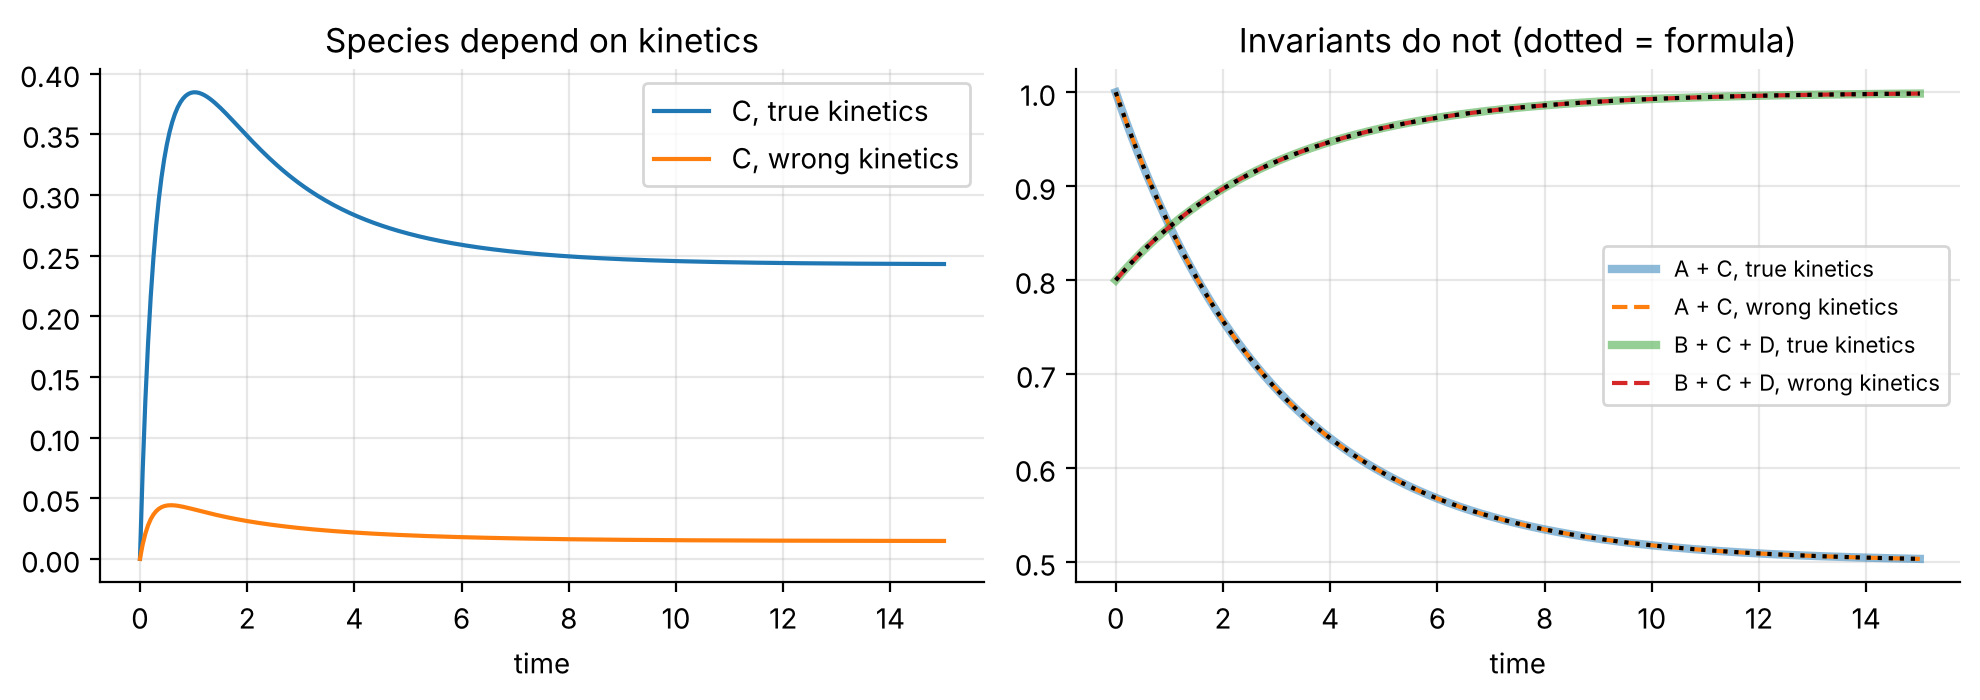

In [13]:
tau = 3.0
c_feed = np.array([0.5, 1.0, 0.0, 0.0])
def cstr(rate_fn):
    return solve_ivp(lambda t, c: (c_feed - c) / tau + S @ rate_fn(c),
                     (0, 15), c0, t_eval=np.linspace(0, 15, 300), rtol=1e-9)

true_run  = cstr(rates)
wrong_run = cstr(lambda c: np.array([0.3 * c[0]**2 * np.sqrt(c[1] + 1e-12), 4.0 * c[2]]))  # made-up kinetics
t = true_run.t
analytic = (W @ c_feed)[:, None] + ((W @ c0) - (W @ c_feed))[:, None] * np.exp(-t / tau)

fig, axs = plt.subplots(1, 2)
axs[0].plot(t, true_run.y[2], label="C, true kinetics")
axs[0].plot(t, wrong_run.y[2], label="C, wrong kinetics")
axs[0].set(xlabel="time", title="Species depend on kinetics"); axs[0].legend()
for k, name in enumerate(["A + C", "B + C + D"]):
    axs[1].plot(t, (W @ true_run.y)[k], lw=3, alpha=0.5, label=f"{name}, true kinetics")
    axs[1].plot(t, (W @ wrong_run.y)[k], ls="--", label=f"{name}, wrong kinetics")
    axs[1].plot(t, analytic[k], ls=":", c="k")
axs[1].set(xlabel="time", title="Invariants do not (dotted = formula)"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Why this matters for learning.** Suppose you want a neural network to learn unknown reaction kinetics from data.
Out of 4 state variables, 2 combinations are already known exactly. You only need to learn the rates $r(c)$
(2 numbers), and you plug them into $S\,r(c)$. The network then *cannot* violate the invariants.
This "known structure + learned closure" pattern is often called **gray-box** or **hybrid** modeling, and it is
one of the most reliable recipes in scientific ML.

## Lesson 3b — When molecules are few: stochastic simulation (Gillespie)

The ODE $\dot c = S\,r(c)$ treats concentrations as smooth numbers. That is fine for a beaker with $10^{20}$ molecules.
It fails in a living cell, a microfluidic droplet, or a nanoliter well handled by a lab robot, where there may be only
tens of molecules of a species. Then *when* each individual reaction happens is random, and the randomness is real
physics, not measurement noise.

The **Gillespie algorithm** (stochastic simulation algorithm, SSA) is an exact Monte Carlo method for this:

1. Compute each reaction's *propensity* $a_j$ (expected events per second, from the current molecule counts).
2. Draw the waiting time to the next event: exponential with rate $a_0 = \sum_j a_j$.
3. Pick which reaction fires, with probability $a_j / a_0$.
4. Update the counts by the column $S_{:,j}$ of the stoichiometric matrix. Repeat.

Step 4 is the mass balance. Because the state only ever changes by a column of $S$, and $w^\top S = 0$,
**the conserved moieties from Lesson 3 hold exactly in every random run** — as integers, with no round-off at all.

$\Omega$ is the system size (molecules per unit concentration). Small $\Omega$ means few molecules.

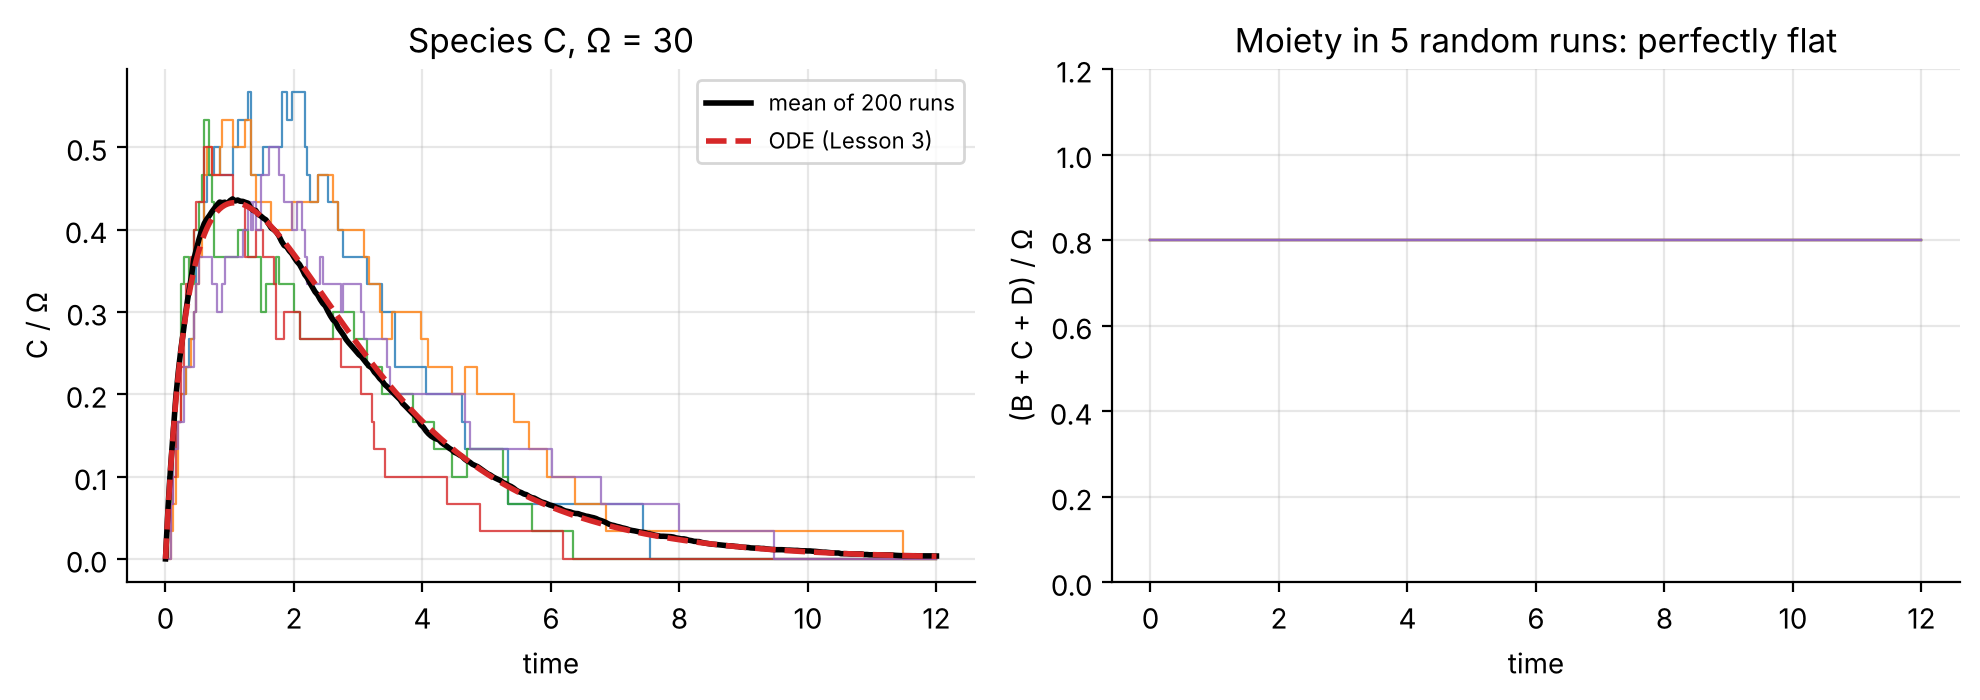

Largest change of any conserved moiety, over all 200 runs and all events: 0 molecules


In [14]:
def gillespie(Omega, t_end, rng):
    x = np.array([round(1.0 * Omega), round(0.8 * Omega), 0, 0])   # molecule counts of A, B, C, D
    t, T, X = 0.0, [0.0], [x.copy()]
    while True:
        a = np.array([k1 * x[0] * x[1] / Omega, k2 * x[2]])         # propensities
        a0 = a.sum()
        if a0 == 0:
            break
        t += rng.exponential(1 / a0)                               # when does the next event happen?
        if t > t_end:
            break
        j = 0 if rng.random() * a0 < a[0] else 1                   # which reaction?
        x = x + S[:, j]                                            # mass balance: apply one column of S
        T.append(t); X.append(x.copy())
    return np.array(T), np.array(X)

def on_grid(T, X, tg):
    return X[np.searchsorted(T, tg, side="right") - 1]            # piecewise-constant counts

def ssa_ensemble(Omega, n_runs, seed=0, t_end=12.0, n_grid=300):
    rng_g = np.random.default_rng(seed)
    tg = np.linspace(0, t_end, n_grid)
    runs, worst = [], 0
    for _ in range(n_runs):
        T, X = gillespie(Omega, t_end, rng_g)
        worst = max(worst, np.abs(W @ X.T - (W @ X[0])[:, None]).max())   # invariant check, every event
        runs.append(on_grid(T, X, tg))
    return tg, np.array(runs), worst

def plot_ssa(Omega, n_runs, seed=0):
    tg, runs, worst = ssa_ensemble(Omega, n_runs, seed)
    fig, axs = plt.subplots(1, 2)
    for r in runs[:5]:
        axs[0].step(tg, r[:, 2] / Omega, where="post", lw=0.8, alpha=0.8)
    axs[0].plot(tg, runs[:, :, 2].mean(0) / Omega, c="k", lw=2, label=f"mean of {n_runs} runs")
    axs[0].plot(batch.t, batch.y[2], c="C3", ls="--", lw=2, label="ODE (Lesson 3)")
    axs[0].set(xlabel="time", ylabel="C / Ω", title=f"Species C, Ω = {Omega}"); axs[0].legend(fontsize=8)
    for r in runs[:5]:
        axs[1].step(tg, (W @ r.T).T[:, 1] / Omega, where="post", lw=0.8)
    axs[1].set(xlabel="time", ylabel="(B + C + D) / Ω", title="Moiety in 5 random runs: perfectly flat",
               ylim=(0, 1.2))
    plt.tight_layout(); plt.show()
    print(f"Largest change of any conserved moiety, over all {n_runs} runs and all events: {worst} molecules")

plot_ssa(Omega=30, n_runs=200)

With only ~30 molecules, single runs zig-zag far from the ODE, yet the *average* of many runs follows it closely.
(Not perfectly: for a reaction like A + B, the average of a product is not the product of averages, so small
systems can drift away from the ODE. That gap is a real effect, and only stochastic simulation shows it.)

### 🎛 Playground 3b — from noisy to deterministic

Slide $\Omega$ up. The runs squeeze onto the ODE: relative fluctuations shrink like $1/\sqrt{\Omega}$.
Whatever you do, the moiety panel stays flat.

In [ ]:
playground(plot_ssa,
           Omega=IntSlider(value=30, min=3, max=1000, step=1),
           n_runs=IntSlider(value=100, min=5, max=300, step=5),
           seed=IntSlider(value=0, min=0, max=50))

## Lesson 4 — Compartment networks in matrix form

Many systems are networks of volumes that exchange mass: tanks and pipes, rooms and air ducts,
organs and blood flow, warehouses and trucks, mesh cells in a simulator, nodes in a graph neural network.

Let $x_i$ be the mass in compartment $i$ and let $F_{ij} \ge 0$ be the rate constant for flow **from $j$ to $i$**.
With linear (first-order) flows:

$$
\dot x = K x, \qquad K = F - \operatorname{diag}\Big(\textstyle\sum_i F_{ij}\Big)
$$

Each column of $K$ sums to zero: what leaves compartment $j$ arrives somewhere else.
So $\mathbf 1^\top K = 0$, and $\frac{d}{dt}\mathbf 1^\top x = 0$.

The exact discrete-time map over a step $\Delta t$ is $x_{t+1} = e^{K\Delta t} x_t$.
Its matrix is **column-stochastic**: entries $\ge 0$ and columns summing to 1. That is a Markov matrix.
Mass conservation and positivity in one object.

In [16]:
def compartment_matrix(F):
    # Build K from non-negative flow constants F[i, j] = rate from j to i.
    F = np.array(F, dtype=float)
    np.fill_diagonal(F, 0.0)
    return F - np.diag(F.sum(axis=0))

F_true = np.array([[0.0, 0.3, 0.0, 0.1],
                   [0.5, 0.0, 0.2, 0.0],
                   [0.0, 0.4, 0.0, 0.3],
                   [0.2, 0.0, 0.6, 0.0]])
K_true = compartment_matrix(F_true)
dt_c = 0.1
A_true = expm(K_true * dt_c)

print("Column sums of K      :", K_true.sum(axis=0).round(12))
print("Column sums of e^{KΔt}:", A_true.sum(axis=0).round(12))
print("Smallest entry of e^{KΔt}:", A_true.min().round(5), "(non-negative)")

Column sums of K      : [ 0.  0. -0.  0.]
Column sums of e^{KΔt}: [1. 1. 1. 1.]
Smallest entry of e^{KΔt}: 0.00052 (non-negative)


## Lesson 5 — Learning the dynamics from data

This is the core Physical AI scenario. You have **noisy sensor data** from a system and want a model that can
predict far into the future (for planning, control, or a digital twin). You do *not* know $F$.

We compare two learners on the same data:

| Model | Parameters | Structure |
|---|---|---|
| **Black box** | full $4\times4$ matrix $A$, fit by least squares: $y_{t+1} \approx A y_t$ | none |
| **Mass-balance structured** | 12 off-diagonal entries $a_{ij} \ge 0$; diagonal set to $1-\sum_i a_{ij}$ | column-stochastic by construction |

The structured model is still fit by plain least squares (with bounds), because
$y_{t+1} - y_t = \sum_{i\neq j} a_{ij}\, y_{t,j}\,(e_i - e_j)$ is linear in the $a_{ij}$:
each parameter moves mass from $j$ to $i$ and the term $(e_i - e_j)$ is the bookkeeping.

In [17]:
def simulate_linear(A, x0, n):
    X = np.empty((n + 1, len(x0))); X[0] = x0
    for k in range(n):
        X[k + 1] = A @ X[k]
    return X

def make_dataset(n_traj, n_steps, noise, rng):
    Y0, Y1 = [], []
    for _ in range(n_traj):
        x0 = rng.dirichlet(np.ones(4))                    # total mass = 1
        X = simulate_linear(A_true, x0, n_steps)
        Y = X + noise * rng.standard_normal(X.shape)      # noisy sensors
        Y0.append(Y[:-1]); Y1.append(Y[1:])
    return np.vstack(Y0), np.vstack(Y1)

def fit_black_box(Y0, Y1):
    # Solve Y1 ≈ Y0 A^T in the least-squares sense.
    return np.linalg.lstsq(Y0, Y1, rcond=None)[0].T

PAIRS = [(i, j) for i in range(4) for j in range(4) if i != j]
def fit_structured(Y0, Y1):
    n = Y0.shape[0]
    D = np.zeros((4 * n, len(PAIRS)))                     # design matrix
    for p, (i, j) in enumerate(PAIRS):
        col = np.zeros((n, 4))
        col[:, i] += Y0[:, j]                             # gain in i ...
        col[:, j] -= Y0[:, j]                             # ... is a loss in j
        D[:, p] = col.ravel()
    target = (Y1 - Y0).ravel()
    a = lsq_linear(D, target, bounds=(0, 1)).x
    A = np.eye(4)
    for p, (i, j) in enumerate(PAIRS):
        A[i, j] += a[p]; A[j, j] -= a[p]
    return A

Y0, Y1 = make_dataset(n_traj=3, n_steps=30, noise=0.03, rng=rng)
A_bb = fit_black_box(Y0, Y1)
A_st = fit_structured(Y0, Y1)
print(f"Training pairs: {len(Y0)}")
print("Column sums, black box :", A_bb.sum(axis=0).round(4))
print("Column sums, structured:", A_st.sum(axis=0).round(4))

Training pairs: 90
Column sums, black box : [1.131  1.0323 0.8579 0.9881]
Column sums, structured: [1. 1. 1. 1.]


Now the real test: a **long rollout** from a new initial state, 10× longer than any training trajectory.
This is what a planner or a model-predictive controller does with a learned model.

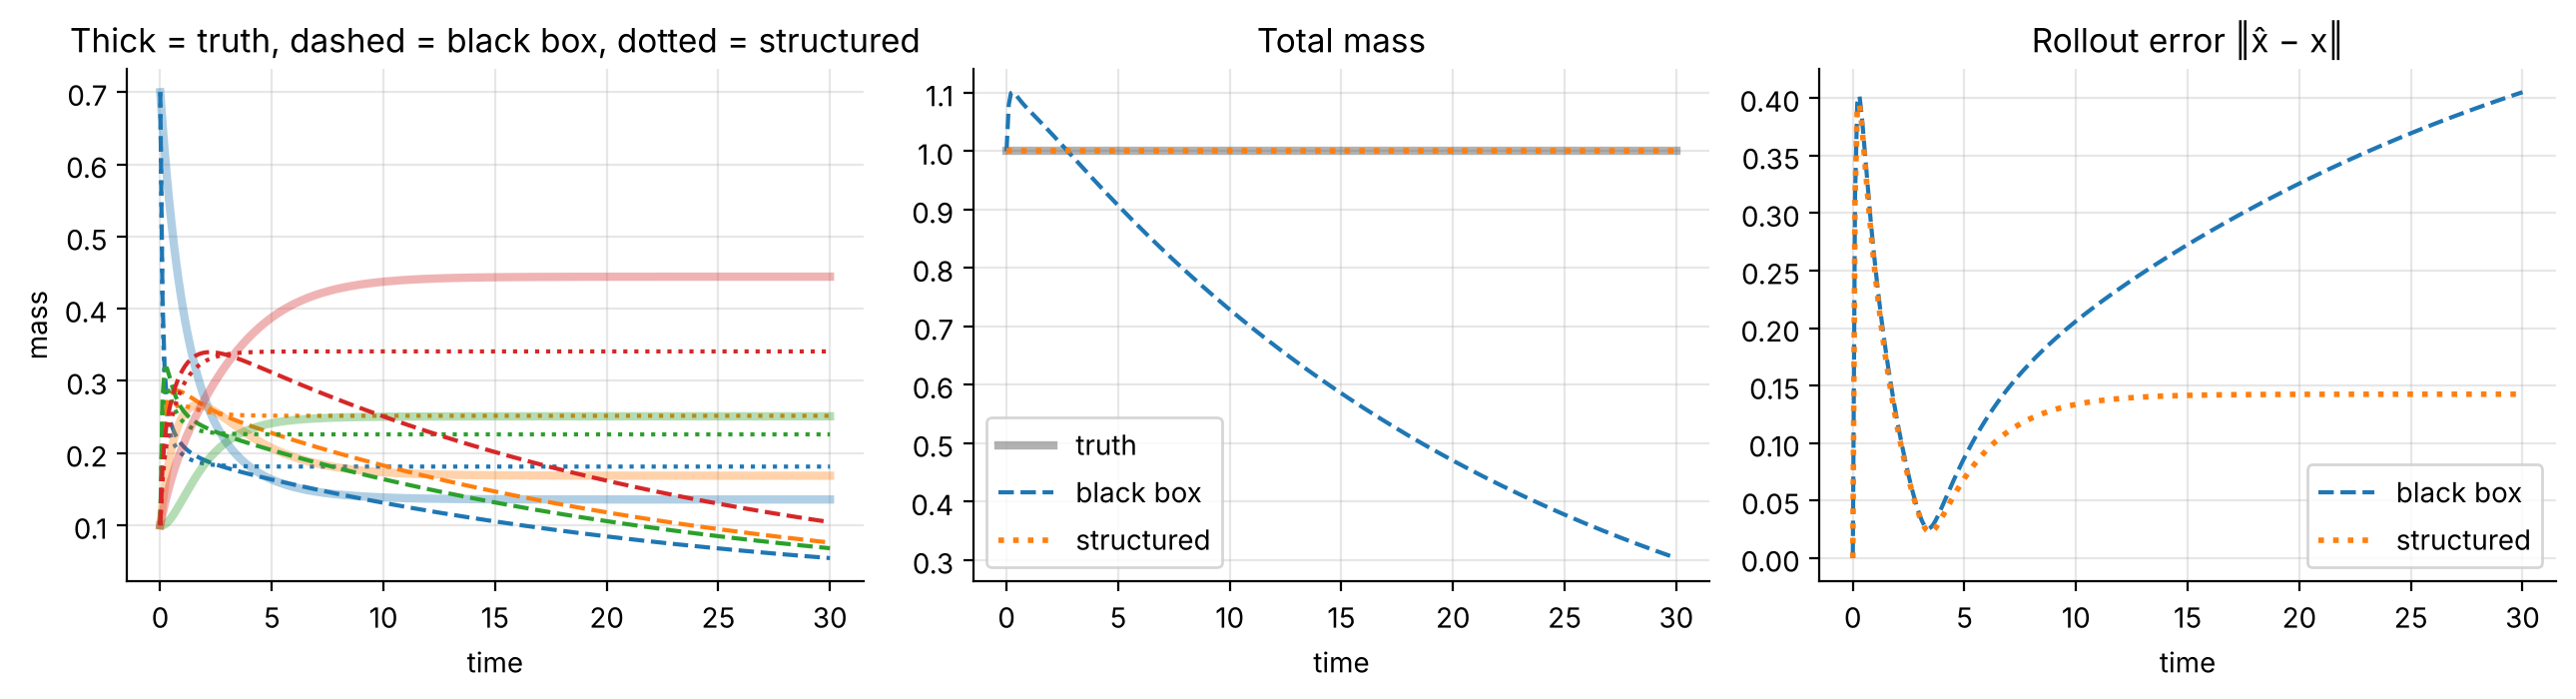

In [18]:
x_test = np.array([0.7, 0.1, 0.1, 0.1])
n_roll = 300
X_true = simulate_linear(A_true, x_test, n_roll)
X_bb   = simulate_linear(A_bb,   x_test, n_roll)
X_st   = simulate_linear(A_st,   x_test, n_roll)
tt = np.arange(n_roll + 1) * dt_c

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for i in range(4):
    axs[0].plot(tt, X_true[:, i], c=f"C{i}", lw=3, alpha=0.35)
    axs[0].plot(tt, X_bb[:, i],   c=f"C{i}", ls="--")
    axs[0].plot(tt, X_st[:, i],   c=f"C{i}", ls=":")
axs[0].set(xlabel="time", ylabel="mass", title="Thick = truth, dashed = black box, dotted = structured")
axs[1].plot(tt, X_true.sum(1), c="k", lw=3, alpha=0.3, label="truth")
axs[1].plot(tt, X_bb.sum(1), "--", label="black box")
axs[1].plot(tt, X_st.sum(1), ":", lw=2, label="structured")
axs[1].set(xlabel="time", title="Total mass"); axs[1].legend()
axs[2].plot(tt, np.linalg.norm(X_bb - X_true, axis=1), "--", label="black box")
axs[2].plot(tt, np.linalg.norm(X_st - X_true, axis=1), ":", lw=2, label="structured")
axs[2].set(xlabel="time", title="Rollout error ‖x̂ − x‖"); axs[2].legend()
plt.tight_layout(); plt.show()

Notice that the structured model is not perfect either: it settles to slightly wrong shares per compartment.
But its total stays exactly right. The black box fits each one-step transition well, yet over a long horizon it slowly loses (or gains) mass.
Least squares on noisy inputs shrinks the matrix towards zero (the "errors-in-variables" bias), and nothing in the
model says that mass must be kept. The structured model cannot drift: its total stays at exactly 1.

Let us check that this is not luck. We repeat the experiment over many random datasets and training sizes.
This is a small 🎲 **Monte Carlo experiment**: the randomness is in the sensor noise and the starting states, and we
report the median over 30 random datasets instead of trusting a single lucky (or unlucky) draw.

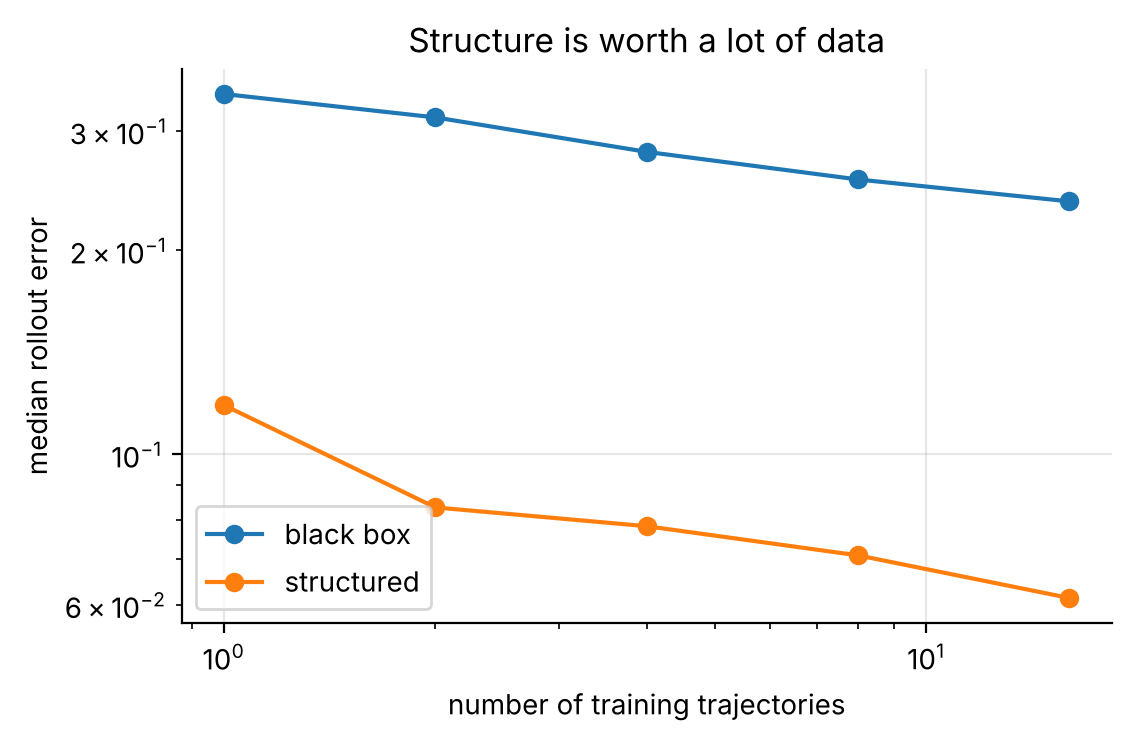

n_traj  black box  structured
     1     0.3401      0.1181
     2     0.3142      0.0835
     4     0.2794      0.0783
     8     0.2544      0.0709
    16     0.2361      0.0614


In [19]:
def rollout_error(A, n=300):
    return np.linalg.norm(simulate_linear(A, x_test, n) - X_true[: n + 1], axis=1).mean()

sizes = [1, 2, 4, 8, 16]
res = {"black box": [], "structured": []}
for n_traj in sizes:
    e_bb, e_st = [], []
    for seed in range(30):
        r = np.random.default_rng(1000 + seed)
        Y0_, Y1_ = make_dataset(n_traj, 30, 0.03, r)
        e_bb.append(rollout_error(fit_black_box(Y0_, Y1_)))
        e_st.append(rollout_error(fit_structured(Y0_, Y1_)))
    res["black box"].append(np.median(e_bb)); res["structured"].append(np.median(e_st))

fig, ax = plt.subplots(figsize=(6, 3.6))
for k, v in res.items():
    ax.loglog(sizes, v, "o-", label=k)
ax.set(xlabel="number of training trajectories", ylabel="median rollout error",
       title="Structure is worth a lot of data"); ax.legend(); plt.show()
print("n_traj  black box  structured")
for n, a, b in zip(sizes, res["black box"], res["structured"]):
    print(f"{n:6d}  {a:9.4f}  {b:10.4f}")

> **Take-away.** A model that respects the mass balance needs far less data for the same long-horizon accuracy,
> and its errors stay *physically plausible*: mass may go to the wrong compartment, but it is never invented
> or lost. For a robot that plans with its model, that difference decides whether plans are safe.

### 🎛 Playground 2 — when does structure matter?

Try: set the noise to 0 (the black box becomes almost perfect: no noise, no bias); then give it very short
trajectories; then lots of noise. Change the seed to draw a new dataset.

In [ ]:
def play_learning(sensor_noise, n_trajectories, steps_per_trajectory, rollout_steps, seed):
    r = np.random.default_rng(seed)
    Y0_, Y1_ = make_dataset(n_trajectories, steps_per_trajectory, sensor_noise, r)
    Xt = simulate_linear(A_true, x_test, rollout_steps)
    models = {"black box": fit_black_box(Y0_, Y1_), "structured": fit_structured(Y0_, Y1_)}
    tt_ = np.arange(rollout_steps + 1) * dt_c
    fig, axs = plt.subplots(1, 2)
    axs[0].plot(tt_, Xt.sum(1), c="k", lw=3, alpha=0.3, label="truth")
    for name, A in models.items():
        Xm = simulate_linear(A, x_test, rollout_steps)
        axs[0].plot(tt_, Xm.sum(1), label=name)
        axs[1].plot(tt_, np.linalg.norm(Xm - Xt, axis=1), label=f"{name}: mean {np.linalg.norm(Xm-Xt,axis=1).mean():.3f}")
    axs[0].set(xlabel="time", title=f"Total mass ({len(Y0_)} training pairs)"); axs[0].legend()
    axs[1].set(xlabel="time", title="Rollout error"); axs[1].legend()
    plt.tight_layout(); plt.show()

playground(play_learning,
           sensor_noise=FloatSlider(value=0.03, min=0.0, max=0.15, step=0.005, readout_format=".3f"),
           n_trajectories=IntSlider(value=3, min=1, max=30),
           steps_per_trajectory=IntSlider(value=30, min=3, max=100),
           rollout_steps=IntSlider(value=300, min=50, max=2000, step=50),
           seed=IntSlider(value=0, min=0, max=50))

## Lesson 6 — Constraining nonlinear learned models

Real systems are nonlinear, so real Physical AI uses flexible function approximators (neural networks, Gaussian
processes, polynomial features...). How do you make *those* respect a mass balance? Three common options:

| Option | How | Conservation | Cost |
|---|---|---|---|
| **A. Soft constraint** ("physics-informed loss") | add $\lambda\,\lVert\text{mass residual}\rVert^2$ to the loss | approximate | one extra loss term |
| **B. Hard projection** | project each prediction onto the set where mass is conserved | exact | one line of code |
| **C. Conservation by construction** | predict **fluxes** between nodes and apply them with $\pm$ bookkeeping | exact, also positivity | design the model around it |

**Test system.** Three tanks in a closed loop. Water flows 1 → 2 → 3 by gravity ($q = k\sqrt h$), and a
saturating pump returns it 3 → 1. Total water is constant.

In [21]:
k12, k23, p_max = 0.5, 0.4, 0.6
def loop_rhs(t, hh):
    h1, h2, h3 = np.maximum(hh, 0)
    q12, q23 = k12 * np.sqrt(h1), k23 * np.sqrt(h2)
    q31 = p_max * h3 / (h3 + 0.2)
    return [q31 - q12, q12 - q23, q23 - q31]

dt_l = 0.1
def loop_traj(h0, n):
    t = np.arange(n + 1) * dt_l
    return solve_ivp(loop_rhs, (0, t[-1]), h0, t_eval=t, rtol=1e-9, atol=1e-11).y.T

# Training data: short noisy trajectories from random starts
noise_l = 0.01
H0, H1 = [], []
for _ in range(20):
    h0 = rng.dirichlet(np.ones(3)) * rng.uniform(1.0, 2.0)
    Y = loop_traj(h0, 40) + noise_l * rng.standard_normal((41, 3))
    H0.append(Y[:-1]); H1.append(Y[1:])
H0, H1 = np.vstack(H0), np.vstack(H1)
dH = H1 - H0

def features(Hm):
    # Generic degree-3 polynomial features: a stand-in for a neural network.
    Hm = np.atleast_2d(Hm)
    cols = [np.ones(len(Hm))]
    n = Hm.shape[1]
    for i in range(n):
        cols.append(Hm[:, i])
        for j in range(i, n):
            cols.append(Hm[:, i] * Hm[:, j])
            for k in range(j, n):
                cols.append(Hm[:, i] * Hm[:, j] * Hm[:, k])
    return np.column_stack(cols)

Phi = features(H0)
print("Training pairs:", len(H0), "  features per sample:", Phi.shape[1])

Training pairs: 800   features per sample: 20


We fit $\Delta h \approx \Phi(h)\,W$ in three ways. All are linear least squares, so the whole difference is in the
structure, not the optimizer.

* **Unconstrained:** ordinary ridge regression.
* **A. Soft:** stack extra "residual" rows $\sqrt{\lambda}\;\Phi W \mathbf 1 \approx 0$ into the same least-squares problem.
  This is exactly what a physics-informed loss does, just with a closed-form solver.
* **B. Hard projection:** after any prediction, remove its mean so the three changes sum to zero:
  $\Delta\hat h \leftarrow \Delta\hat h - \tfrac13 (\mathbf 1^\top \Delta\hat h)\,\mathbf 1$.
  (For this model it is the same as fitting with the constraint $W\mathbf 1 = 0$.)

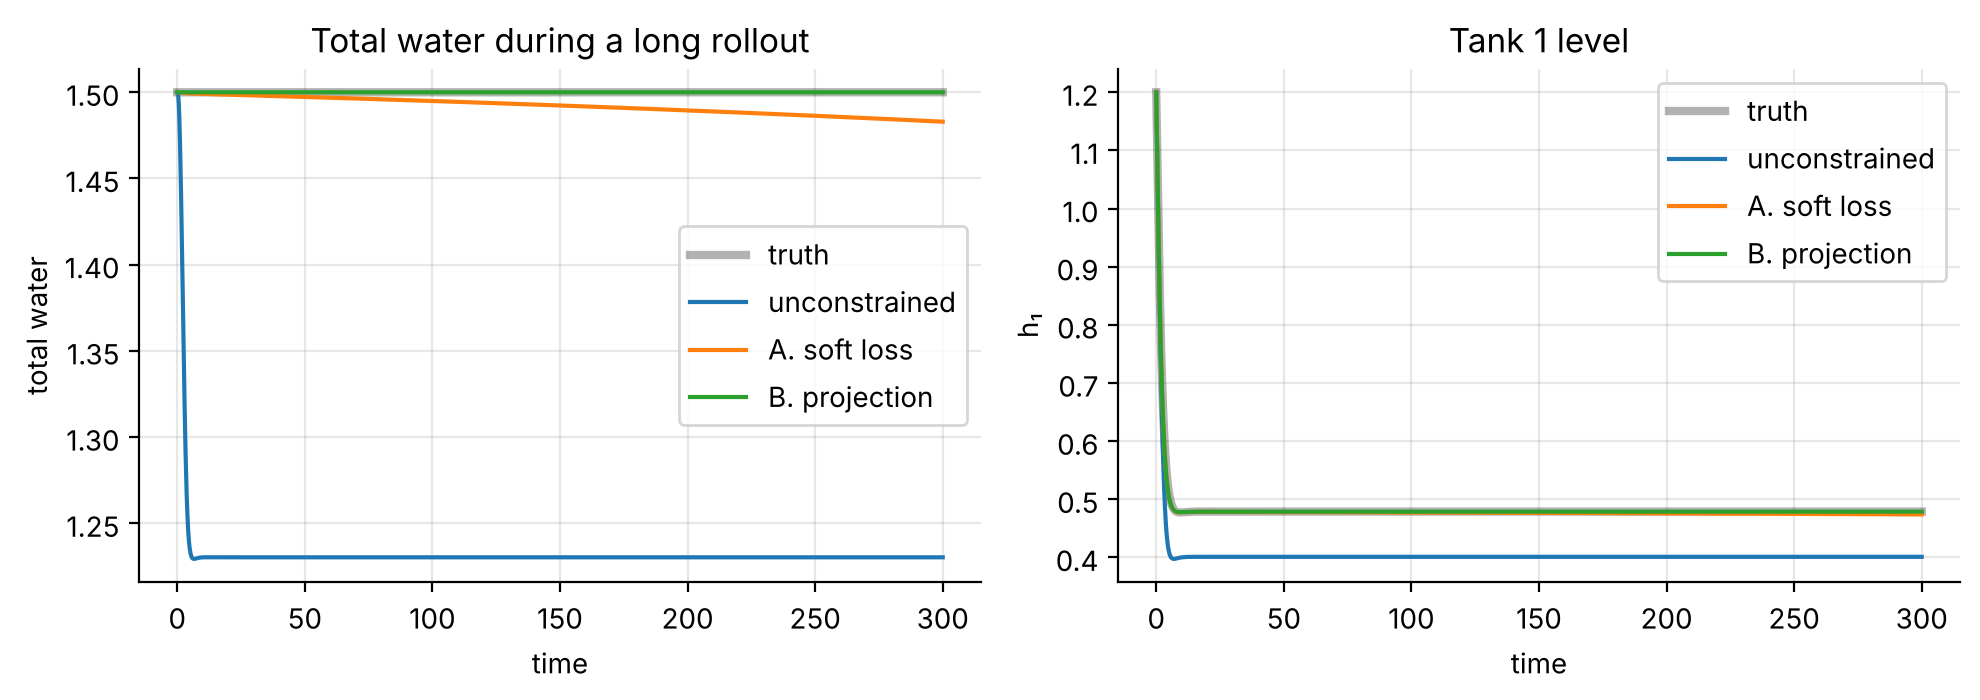

model            final mass error  mean state error
unconstrained           -2.70e-01            0.1677
A. soft loss            -1.71e-02            0.0103
B. projection            0.00e+00            0.0076


In [22]:
ridge = 1e-6
def fit_ridge(Phi, Y, lam_soft=0.0):
    n, p = Phi.shape; m = Y.shape[1]
    # Unknown: vec(W) of length p*m. Data rows: (I_m ⊗ Phi) vec(W) = vec(Y)
    D = np.kron(np.eye(m), Phi)
    rows, rhs = [D], [Y.T.ravel()]
    if lam_soft > 0:   # physics rows: sum over outputs of predictions = 0
        rows.append(np.sqrt(lam_soft) * np.kron(np.ones((1, m)), Phi)); rhs.append(np.zeros(n))
    rows.append(np.sqrt(ridge) * np.eye(p * m)); rhs.append(np.zeros(p * m))
    w = np.linalg.lstsq(np.vstack(rows), np.concatenate(rhs), rcond=None)[0]
    return w.reshape(m, p).T

W_free = fit_ridge(Phi, dH)
W_soft = fit_ridge(Phi, dH, lam_soft=100.0)

def step_free(h): return h + features(h)[0] @ W_free
def step_soft(h): return h + features(h)[0] @ W_soft
def step_proj(h):
    d = features(h)[0] @ W_free
    return h + d - d.mean()            # hard projection onto sum(Δh) = 0

def rollout(step, h0, n):
    Hs = [np.array(h0, float)]
    for _ in range(n):
        Hs.append(step(Hs[-1]))
    return np.array(Hs)

h_test = np.array([1.2, 0.1, 0.2]); n_long = 3000   # 300 s, vs 4 s per training trajectory
H_true = loop_traj(h_test, n_long)
runs = {"unconstrained": rollout(step_free, h_test, n_long),
        "A. soft loss":  rollout(step_soft, h_test, n_long),
        "B. projection": rollout(step_proj, h_test, n_long)}

tl = np.arange(n_long + 1) * dt_l
fig, axs = plt.subplots(1, 2)
axs[0].plot(tl, H_true.sum(1), c="k", lw=3, alpha=0.3, label="truth")
for name, Hr in runs.items():
    axs[0].plot(tl, Hr.sum(1), label=name)
axs[0].set(xlabel="time", ylabel="total water", title="Total water during a long rollout"); axs[0].legend()
axs[1].plot(tl, H_true[:, 0], c="k", lw=3, alpha=0.3, label="truth")
for name, Hr in runs.items():
    axs[1].plot(tl, Hr[:, 0], label=name)
axs[1].set(xlabel="time", ylabel="h₁", title="Tank 1 level"); axs[1].legend()
plt.tight_layout(); plt.show()

print(f"{'model':15s} {'final mass error':>17s} {'mean state error':>17s}")
for name, Hr in runs.items():
    print(f"{name:15s} {Hr[-1].sum()-H_true[-1].sum():17.2e} {np.linalg.norm(Hr-H_true,axis=1).mean():17.4f}")

Read the table carefully:

* The **unconstrained** model drifts: a tiny bias per step adds up over 3000 steps.
* The **soft** loss reduces the drift but cannot remove it. Its size depends on $\lambda$, on the data, and on how far the
  rollout wanders from the training data. A soft constraint is a *wish*, not a guarantee.
* The **projection** conserves mass exactly, with no retraining. Its weakness: it can push a level below zero, because
  it spreads the correction evenly instead of taking it from where the water actually is.

### 🎛 Playground 3 — how strong must the physics loss be?

Slide λ from tiny to huge. The drift shrinks but only reaches zero in the limit, while the projection is exact at any λ.
Also try more sensor noise and a longer rollout.

In [ ]:
def play_soft_loss(lam, rollout_seconds):
    n = int(rollout_seconds / dt_l)
    Ws = fit_ridge(Phi, dH, lam_soft=lam)
    Ht = H_true[: n + 1] if n <= n_long else loop_traj(h_test, n)
    fig, ax = plt.subplots()
    ax.plot(np.arange(n + 1) * dt_l, Ht.sum(1), c="k", lw=3, alpha=0.3, label="truth")
    for name, step in [("unconstrained", step_free),
                       (f"soft, λ = {lam:.3g}", lambda h: h + features(h)[0] @ Ws),
                       ("projection", step_proj)]:
        Hr = rollout(step, h_test, n)
        ax.plot(np.arange(n + 1) * dt_l, Hr.sum(1), label=f"{name}: final error {Hr[-1].sum()-Ht[-1].sum():+.1e}")
    ax.set(xlabel="time", ylabel="total water", title="Total water during rollout"); ax.legend(); plt.show()

playground(play_soft_loss,
           lam=FloatLogSlider(value=100.0, base=10, min=-3, max=6, step=0.25),
           rollout_seconds=FloatSlider(value=300, min=20, max=600, step=20))

### Option C — conservation by construction: a mass-conserving message-passing layer

Graph network simulators for fluids, cloth, and granular media pass "messages" along edges. Make the message a
**flux** and apply it with $\pm$ bookkeeping, and the network conserves mass for *any* weights, even random ones.

We use the **donor-cell** form: a learned non-negative rate $r_{ij}\ge0$ times the mass of the *donor* node $j$:

$$
\text{flux}_{j\to i} = r_{ij}(x_i, x_j)\; x_j,\qquad
x_i \leftarrow x_i + \Delta t \Big(\sum_j \text{flux}_{j\to i} - \sum_j \text{flux}_{i\to j}\Big)
$$

Because each node only gives away what it has, masses also stay $\ge 0$ as long as $\Delta t \sum_i r_{ij} \le 1$.
Below, the "network" is an **untrained** two-layer MLP with random weights on a random graph.

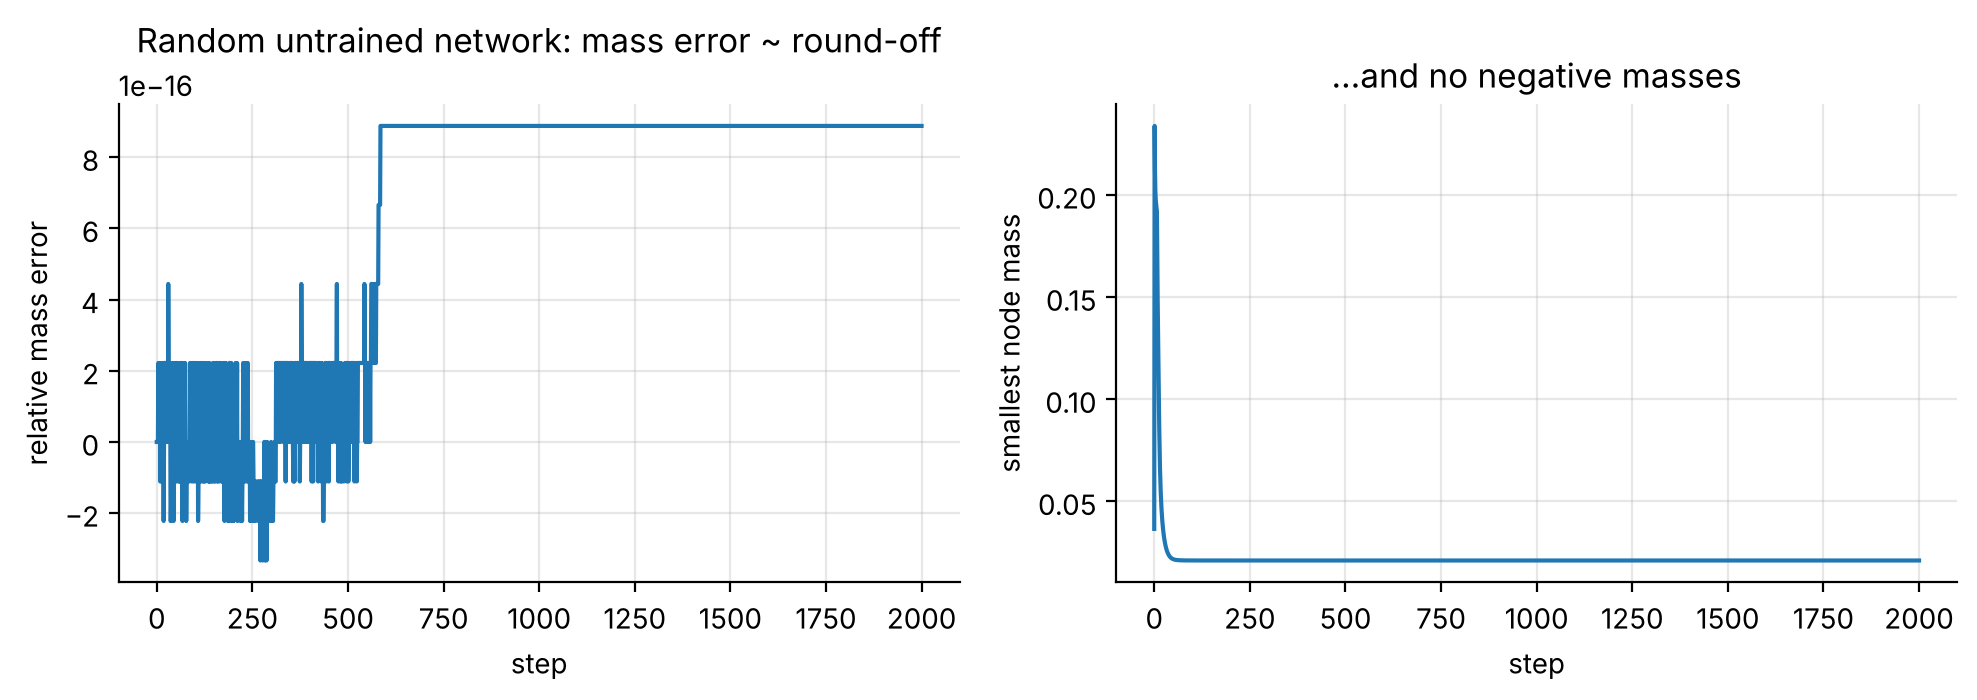

132 edges, max |relative mass error| over 2000 steps: 8.9e-16


In [24]:
def softplus(z): return np.log1p(np.exp(-np.abs(z))) + np.maximum(z, 0)

class ConservingMessagePassing:
    # Donor-cell flux layer. The rate MLP can be anything; conservation does not depend on it.
    def __init__(self, n_hidden, rng):
        self.W1 = rng.standard_normal((2, n_hidden)); self.b1 = rng.standard_normal(n_hidden)
        self.W2 = rng.standard_normal(n_hidden) / np.sqrt(n_hidden)
    def rate(self, xi, xj):                        # MLP -> non-negative rate
        z = np.tanh(np.stack([xi, xj], -1) @ self.W1 + self.b1)
        return softplus(z @ self.W2)
    def step(self, x, edges, dt):
        src, dst = edges[:, 0], edges[:, 1]        # flux goes src -> dst
        r = self.rate(x[dst], x[src])
        r = np.minimum(r, 0.9 / (dt * np.bincount(src, minlength=len(x))[src]))  # positivity limiter
        flux = r * x[src]
        dx = np.zeros_like(x)
        np.add.at(dx, dst,  flux)                  # what arrives ...
        np.add.at(dx, src, -flux)                  # ... is exactly what left
        return x + dt * dx

n_nodes = 30
edges = np.array([(i, j) for i in range(n_nodes) for j in range(n_nodes)
                  if i != j and rng.random() < 0.15])
layer = ConservingMessagePassing(16, rng)
x = rng.exponential(1.0, n_nodes)
M0 = x.sum(); totals, mins = [M0], [x.min()]
for _ in range(2000):
    x = layer.step(x, edges, dt=0.05)
    totals.append(x.sum()); mins.append(x.min())

fig, axs = plt.subplots(1, 2)
axs[0].plot(np.array(totals) / M0 - 1)
axs[0].set(xlabel="step", ylabel="relative mass error", title="Random untrained network: mass error ~ round-off")
axs[1].plot(mins); axs[1].set(xlabel="step", ylabel="smallest node mass", title="...and no negative masses")
plt.tight_layout(); plt.show()
print(f"{len(edges)} edges, max |relative mass error| over 2000 steps: {np.max(np.abs(np.array(totals)/M0-1)):.1e}")

This is the most important idea in the notebook:

> **Do not ask a network to learn conservation. Build a model in which non-conservation cannot be expressed.**
> Then all of its capacity goes into the part you actually do not know: *how fast* mass moves, not *whether it is kept*.

Training such a layer (in PyTorch or JAX) is ordinary gradient descent on prediction error, because every operation above is
differentiable. Lesson 5's structured model is the linear special case: $r_{ij}$ is a constant.

## Lesson 7 — A robot's digital twin: noticing a spill

A robot arm pours a drink from a cup into a glass.

* A **wrist force sensor** measures the cup's mass. It is noisy (±3 g), because the arm accelerates.
* The glass stands on a **scale**: accurate (±0.3 g).
* Neither sensor measures spilling directly.

Draw two control volumes, the cup and the glass. Let $q$ be the flow that lands in the glass and $s$ the flow that misses it:

$$
\dot m_\text{cup} = -(q + s), \qquad \dot m_\text{glass} = q
$$

The glass gives $q$, the cup gives $q + s$, so the **difference is the spill rate**. We turn this mass balance into a
**Kalman filter** with state $[m_\text{cup}, m_\text{glass}, q, s]$, where $q$ and $s$ are modeled as slowly drifting
(random walks). The filter fuses both sensors with the physics and estimates the unmeasured spill in real time.

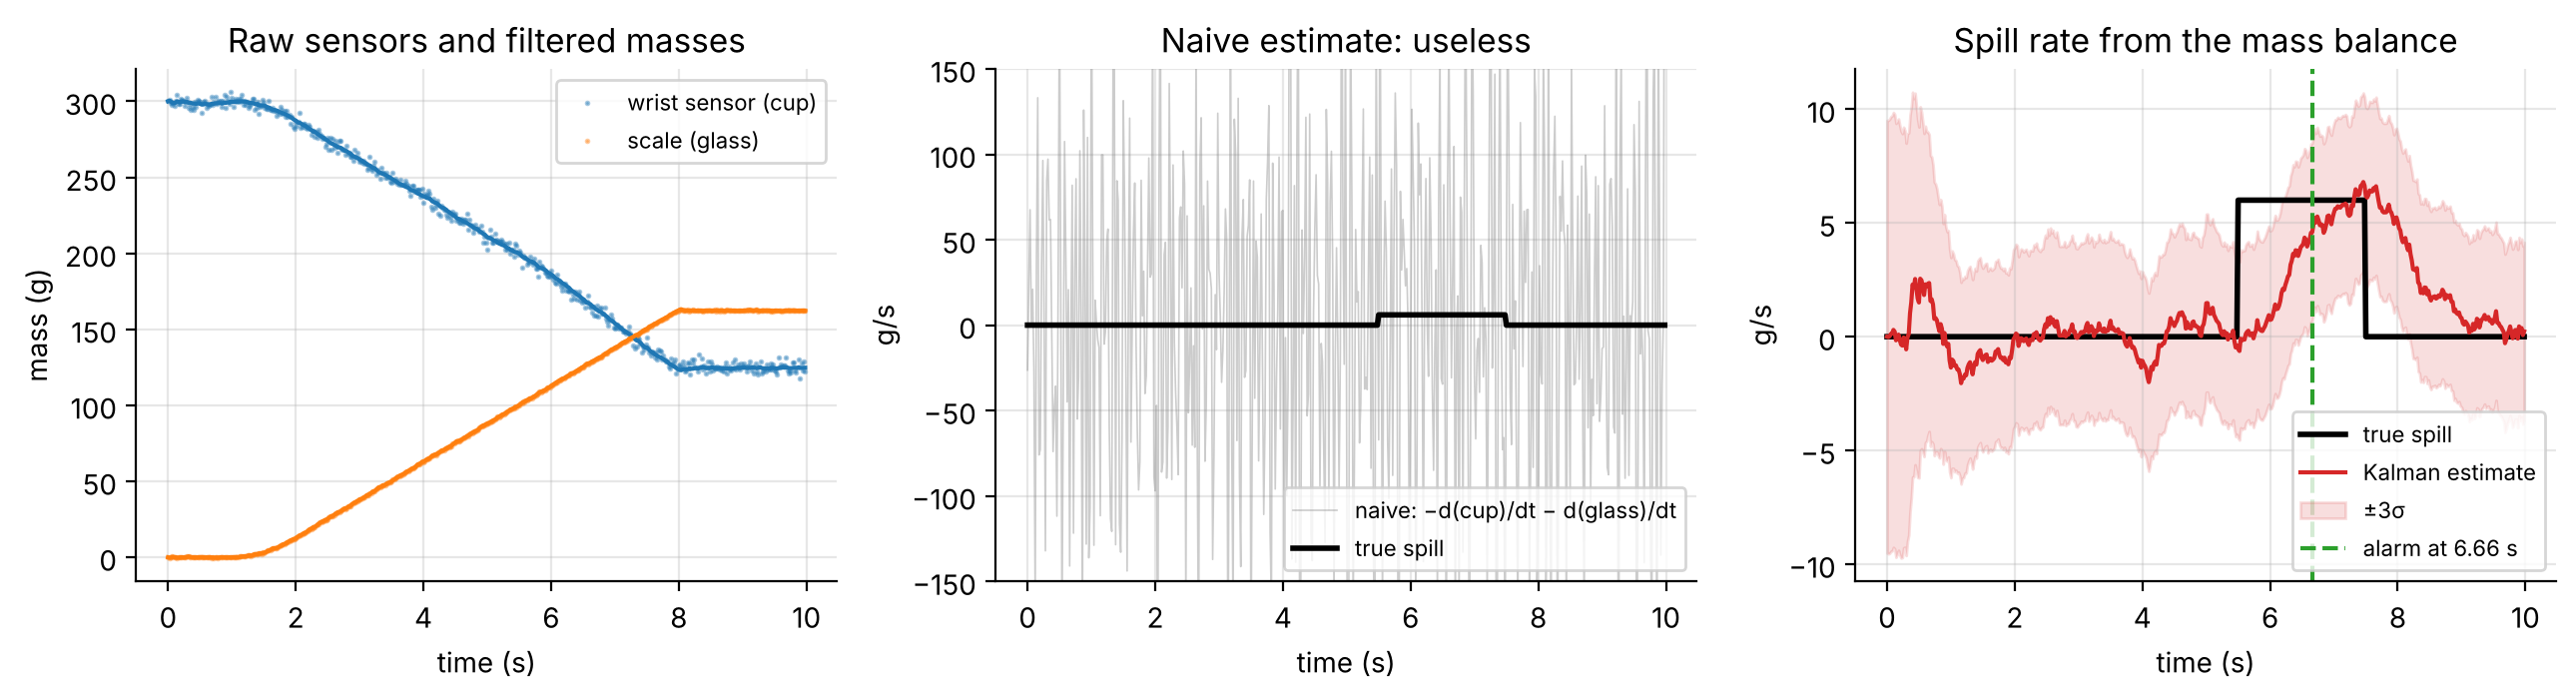

True spill: 12.0 g from 5.50 s. Estimated: 14.3 g.
Alarm at 6.66 s, 1.16 s after the spill began.


In [25]:
def pour_twin(sig_wrist=3.0, spill_rate=6.0, spill_start=5.5, filter_spill_agility=1.5,
              alarm_sigmas=3.0, seed=7, show=True):
    r = np.random.default_rng(seed)
    dt_p, T_p = 0.02, 10.0                                   # 50 Hz, 10 s
    tp = np.arange(0, T_p, dt_p)
    # --- the true world (unknown to the robot) ---
    q_true = np.clip((tp - 1.0) / 1.0, 0, 1) * 25 * (tp < 8.0)                    # g/s into the glass
    s_true = np.where((tp >= spill_start) & (tp < spill_start + 2.0), spill_rate, 0.0)  # g/s spill
    m_cup = 300.0 - np.cumsum((q_true + s_true) * dt_p)
    m_gls = np.cumsum(q_true * dt_p)
    sig_scale = 0.3
    y = np.column_stack([m_cup + sig_wrist * r.standard_normal(len(tp)),
                         m_gls + sig_scale * r.standard_normal(len(tp))])
    # --- Kalman filter built from the mass balance ---
    F = np.array([[1, 0, -dt_p, -dt_p],     # cup loses q + s
                  [0, 1,  dt_p,  0   ],     # glass gains q
                  [0, 0,  1,     0   ],     # q drifts slowly
                  [0, 0,  0,     1   ]])    # s drifts slowly
    H = np.array([[1, 0, 0, 0],
                  [0, 1, 0, 0]])
    Q = np.diag([1e-4, 1e-4, 30.0**2 * dt_p, filter_spill_agility**2 * dt_p])
    R = np.diag([sig_wrist**2, sig_scale**2])
    xk = np.array([y[0, 0], y[0, 1], 0.0, 0.0]); P = np.diag([10.0, 1.0, 10.0, 10.0])
    est, s_std = [], []
    for yk in y:
        xk = F @ xk;  P = F @ P @ F.T + Q                        # predict with the mass balance
        Sk = H @ P @ H.T + R;  Kk = P @ H.T @ np.linalg.inv(Sk)  # update with both sensors
        xk = xk + Kk @ (yk - H @ xk);  P = (np.eye(4) - Kk @ H) @ P
        est.append(xk.copy()); s_std.append(np.sqrt(P[3, 3]))
    est, s_std = np.array(est), np.array(s_std)
    # --- alarm: spill estimate above k sigma for 0.2 s in a row ---
    above = est[:, 3] > alarm_sigmas * s_std
    run = np.convolve(above, np.ones(10, int), "full")[: len(tp)]
    alarm_t = tp[np.argmax(run >= 10)] if np.any(run >= 10) else None
    if show:
        fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
        axs[0].plot(tp, y[:, 0], ".", ms=2, alpha=0.4, label="wrist sensor (cup)")
        axs[0].plot(tp, y[:, 1], ".", ms=2, alpha=0.4, label="scale (glass)")
        axs[0].plot(tp, est[:, 0], c="C0"); axs[0].plot(tp, est[:, 1], c="C1")
        axs[0].set(xlabel="time (s)", ylabel="mass (g)", title="Raw sensors and filtered masses")
        axs[0].legend(fontsize=8)
        naive = -np.gradient(y[:, 0], dt_p) - np.gradient(y[:, 1], dt_p)      # differentiate raw data
        axs[1].plot(tp, naive, c="gray", alpha=0.4, lw=0.6, label="naive: −d(cup)/dt − d(glass)/dt")
        axs[1].plot(tp, s_true, c="k", lw=2, label="true spill")
        axs[1].set(xlabel="time (s)", ylabel="g/s", title="Naive estimate: useless", ylim=(-150, 150))
        axs[1].legend(fontsize=8)
        axs[2].plot(tp, s_true, c="k", lw=2, label="true spill")
        axs[2].plot(tp, est[:, 3], c="C3", label="Kalman estimate")
        axs[2].fill_between(tp, est[:, 3] - alarm_sigmas * s_std, est[:, 3] + alarm_sigmas * s_std,
                            color="C3", alpha=0.15, label=f"±{alarm_sigmas:g}σ")
        if alarm_t is not None:
            axs[2].axvline(alarm_t, c="C2", ls="--", label=f"alarm at {alarm_t:.2f} s")
        axs[2].set(xlabel="time (s)", ylabel="g/s", title="Spill rate from the mass balance")
        axs[2].legend(fontsize=8)
        plt.tight_layout(); plt.show()
        print(f"True spill: {s_true.sum()*dt_p:.1f} g from {spill_start:.2f} s. "
              f"Estimated: {np.maximum(est[:, 3], 0).sum()*dt_p:.1f} g.")
        if alarm_t is None:
            print("No alarm.")
        elif alarm_t < spill_start:
            print(f"FALSE alarm at {alarm_t:.2f} s (before the spill).")
        else:
            print(f"Alarm at {alarm_t:.2f} s, {alarm_t - spill_start:.2f} s after the spill began.")
    return alarm_t

pour_twin();

### 🎛 Playground 4 — the spill detector

Try: a noisier wrist sensor; a small spill of 2 g/s; a very "agile" filter (it reacts fast but also to noise);
a 2σ threshold (faster alarms, more false ones). Change the seed to test the same settings on new noise.

In [ ]:
def play_pour(wrist_noise_g, spill_g_per_s, spill_start_s, filter_spill_agility, alarm_sigmas, seed):
    pour_twin(wrist_noise_g, spill_g_per_s, spill_start_s, filter_spill_agility, alarm_sigmas, seed)

playground(play_pour,
           wrist_noise_g=FloatSlider(value=3.0, min=0.2, max=10.0, step=0.2),
           spill_g_per_s=FloatSlider(value=6.0, min=0.0, max=20.0, step=0.5),
           spill_start_s=FloatSlider(value=5.5, min=2.0, max=7.5, step=0.1),
           filter_spill_agility=FloatLogSlider(value=1.5, base=10, min=-1, max=1.5, step=0.1),
           alarm_sigmas=FloatSlider(value=3.0, min=1.0, max=5.0, step=0.5),
           seed=IntSlider(value=7, min=0, max=50))

**What the robot gains.** Differentiating raw sensor data amplifies noise until the signal disappears.
The mass balance gives the filter a model of how the masses *must* move, so it can average noise over time
without lagging behind the real flows. The unmeasured quantity (spill) falls out as the part of the
budget that does not close.

The same pattern is used for leak detection in pipelines, drift detection in batteries (charge balance instead
of mass balance), contamination tracking in labs with automated pipetting, and inventory checks in robotic warehouses.
With these sensors the alarm comes about one second after the spill starts, when roughly 6 g are lost.
A better wrist sensor or a faster filter shortens that delay; Playground 4 lets you feel the trade-off with false alarms.

## Lesson 7b — Monte Carlo evaluation: is the spill detector good enough?

One run with one alarm proves nothing. Before a robot gets a safety feature, we need numbers like
"false alarms in fewer than 2 % of clean pours" and "90 % of spills caught within 1.5 s".
Only Monte Carlo can give them: run the digital twin many times with fresh random sensor noise,
with and without a spill, and count.

This is a **Monte Carlo experiment over the detector**, not over the physics: every run uses the same mass balance.

100 random pours per cell (fresh sensor noise each time)

threshold  false alarms  3 g/s caught  6 g/s caught  median delay (6 g/s)
     1.0σ           33%           76%           76%                 0.62s
     1.5σ            3%           94%           94%                 0.74s
     2.0σ            0%           99%          100%                 0.86s
     3.0σ            0%            7%          100%                 1.14s
     4.0σ            0%            0%          100%                 1.56s


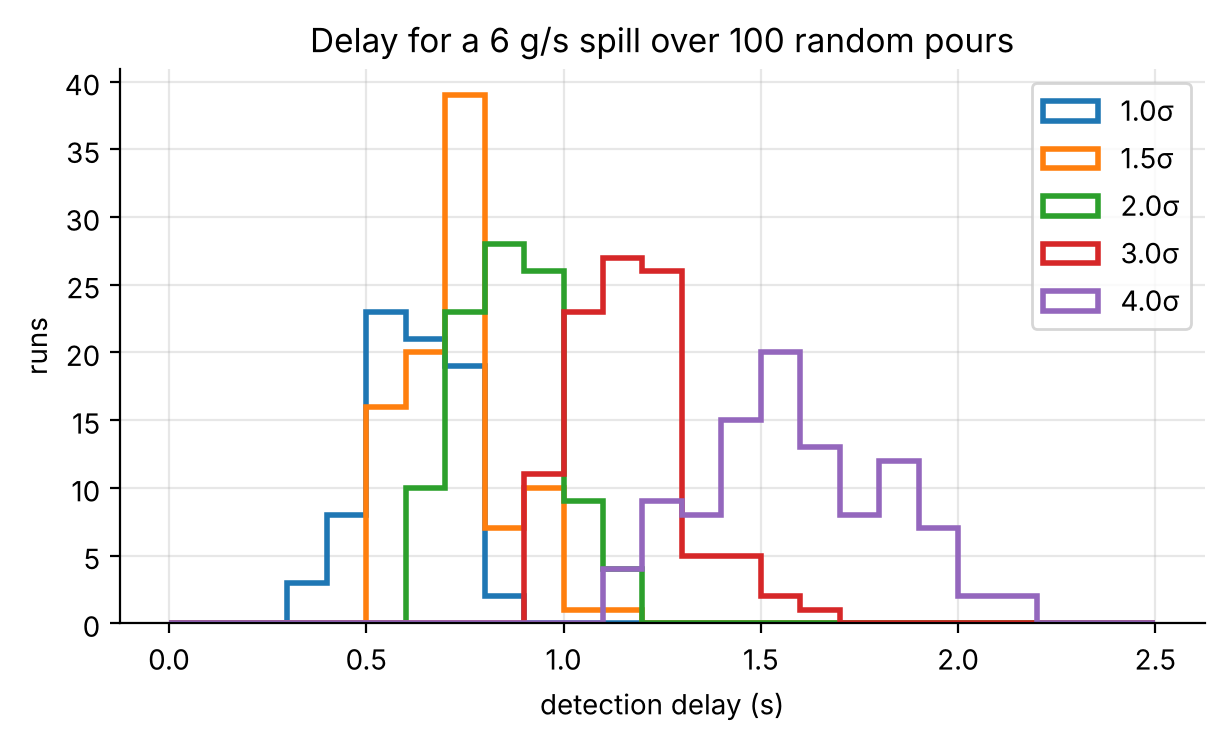

In [27]:
thresholds = [1.0, 1.5, 2.0, 3.0, 4.0]
spill_sizes = [3.0, 6.0]                       # g/s: a small and a clear spill
n_runs_det = 100
rows, delays_by_k = [], {}
for k in thresholds:
    # clean pours: any alarm is a false alarm
    false_clean = np.mean([pour_twin(alarm_sigmas=k, spill_rate=0.0, seed=10_000 + i, show=False) is not None
                           for i in range(n_runs_det)])
    caught = {}
    for sr in spill_sizes:
        alarms = [pour_twin(alarm_sigmas=k, spill_rate=sr, seed=20_000 + i, show=False) for i in range(n_runs_det)]
        on_time = [a - 5.5 for a in alarms if a is not None and a >= 5.5]
        caught[sr] = len(on_time) / n_runs_det
        if sr == 6.0:
            delays_by_k[k] = np.array(on_time)
    rows.append((k, false_clean, caught[3.0], caught[6.0],
                 np.median(delays_by_k[k]) if len(delays_by_k[k]) else np.nan))

print(f"{n_runs_det} random pours per cell (fresh sensor noise each time)\n")
print(f"{'threshold':>9s} {'false alarms':>13s} {'3 g/s caught':>13s} {'6 g/s caught':>13s} {'median delay (6 g/s)':>21s}")
for k, fa, c3, c6, md_ in rows:
    print(f"{k:8.1f}σ {fa:13.0%} {c3:13.0%} {c6:13.0%} {md_:20.2f}s")

fig, ax = plt.subplots(figsize=(7, 3.6))
for k in thresholds:
    if len(delays_by_k[k]):
        ax.hist(delays_by_k[k], bins=np.linspace(0, 2.5, 26), histtype="step", lw=2, label=f"{k}σ")
ax.set(xlabel="detection delay (s)", ylabel="runs", title="Delay for a 6 g/s spill over 100 random pours")
ax.legend(); plt.show()

The table is the honest trade-off. A low threshold catches small spills and reacts sooner, but cries wolf on clean
pours. A high threshold never cries wolf, but misses small spills and reacts later. Around 2σ looks like a good
compromise here: no false alarms in 100 clean pours, nearly every 3 g/s and 6 g/s spill caught, the big ones in under
a second. At 3σ most small spills slip through. At 1σ the alarm so often fires *before* the spill that the
real spill counts as caught less often. Note the limit of this evidence: "0 out of 100" still allows a true false-alarm rate of up to about 3 %
(95 % confidence). Safety claims need many more runs. Monte Carlo makes the choice explicit and measurable.
(The data-size study in Lesson 5, repeated over 30 random datasets, was the same kind of experiment.)

## Lesson 7c — Sequential Monte Carlo: a particle filter for a leaking tank

The Kalman filter assumes linear dynamics and bell-shaped (Gaussian) uncertainty. Many mass-balance problems break both:

* Torricelli outflow $\propto\sqrt h$ is nonlinear.
* A leak size cannot be negative, and a leak appears *suddenly*. Right after it appears, the belief is
  "probably no leak, but maybe a leak of some size": a spike at zero plus a spread. Not a bell curve.

A **particle filter** (sequential Monte Carlo) handles this by brute force. It keeps a cloud of guesses ("particles"),
each a full hypothesis of the hidden state — here *(level, leak size)*:

1. **Predict:** move every particle with the mass-balance model, plus random disturbances (including a small chance that a leak appears).
2. **Weigh:** give each particle a weight according to how well it explains the new level measurement.
3. **Resample:** clone heavy particles, drop light ones. Repeat.

Robots use exactly this algorithm to know where they are (Monte Carlo localization). Here the physics inside is a mass balance.

**Scenario:** the tank from Lesson 1, with a known, measured pump flow of 0.6 L/s. An ultrasonic sensor measures the level
every 2 s with ±1 cm noise. At $t = 500$ s a crack opens: an extra hole of 0.5 cm².

In [28]:
def outflow(hh, area_hole):
    return Cd * area_hole * np.sqrt(2 * g * np.maximum(hh, 0))

q_pump, dt_pf, T_pf, sig_level = 6e-4, 2.0, 1400.0, 0.01
t_pf = np.arange(0, T_pf + dt_pf, dt_pf)
leak_true = np.where(t_pf >= 500, 0.5e-4, 0.0)                 # m^2, unknown to the filter
h_t = np.empty(len(t_pf)); h_t[0] = (q_pump / (Cd * a_out))**2 / (2 * g)   # start at steady state
for k in range(len(t_pf) - 1):
    h_t[k + 1] = h_t[k] + dt_pf * (q_pump - outflow(h_t[k], a_out + leak_true[k])) / A_tank
rng_pf = np.random.default_rng(5)
y_level = h_t + sig_level * rng_pf.standard_normal(len(t_pf))

# --- particle filter ---
n_pf = 3000
h_p = y_level[0] + sig_level * rng_pf.standard_normal(n_pf)
leak_p = np.zeros(n_pf)
p_jump, leak_max = 0.003, 2e-4                    # prior: a leak appears rarely, size up to 2 cm^2
leak_mean, leak_lo, leak_hi, p_leak, ess_log = [], [], [], [], []
for k, yk in enumerate(y_level):
    if k > 0:
        # 1) predict with the mass balance (+ disturbances)
        jump = rng_pf.random(n_pf) < p_jump
        leak_p = np.where(jump, rng_pf.uniform(0, leak_max, n_pf), leak_p)
        leak_p = np.maximum(leak_p + 1e-7 * rng_pf.standard_normal(n_pf), 0)
        h_p = h_p + dt_pf * (q_pump - outflow(h_p, a_out + leak_p)) / A_tank
        h_p += 2e-3 * rng_pf.standard_normal(n_pf)
    # 2) weigh by the measurement likelihood
    logw = -0.5 * ((yk - h_p) / sig_level)**2
    w = np.exp(logw - logw.max()); w /= w.sum()
    ess_log.append(1 / np.sum(w**2))
    # 3) resample (systematic)
    idx = np.searchsorted(np.cumsum(w), (rng_pf.random() + np.arange(n_pf)) / n_pf)
    idx = np.minimum(idx, n_pf - 1)
    h_p, leak_p = h_p[idx], leak_p[idx]
    leak_mean.append(leak_p.mean()); p_leak.append(np.mean(leak_p > 0.15e-4))
    leak_lo.append(np.percentile(leak_p, 5)); leak_hi.append(np.percentile(leak_p, 95))

leak_mean, p_leak = np.array(leak_mean), np.array(p_leak)
alarm_pf = t_pf[np.argmax(p_leak > 0.95)] if np.any(p_leak > 0.95) else None

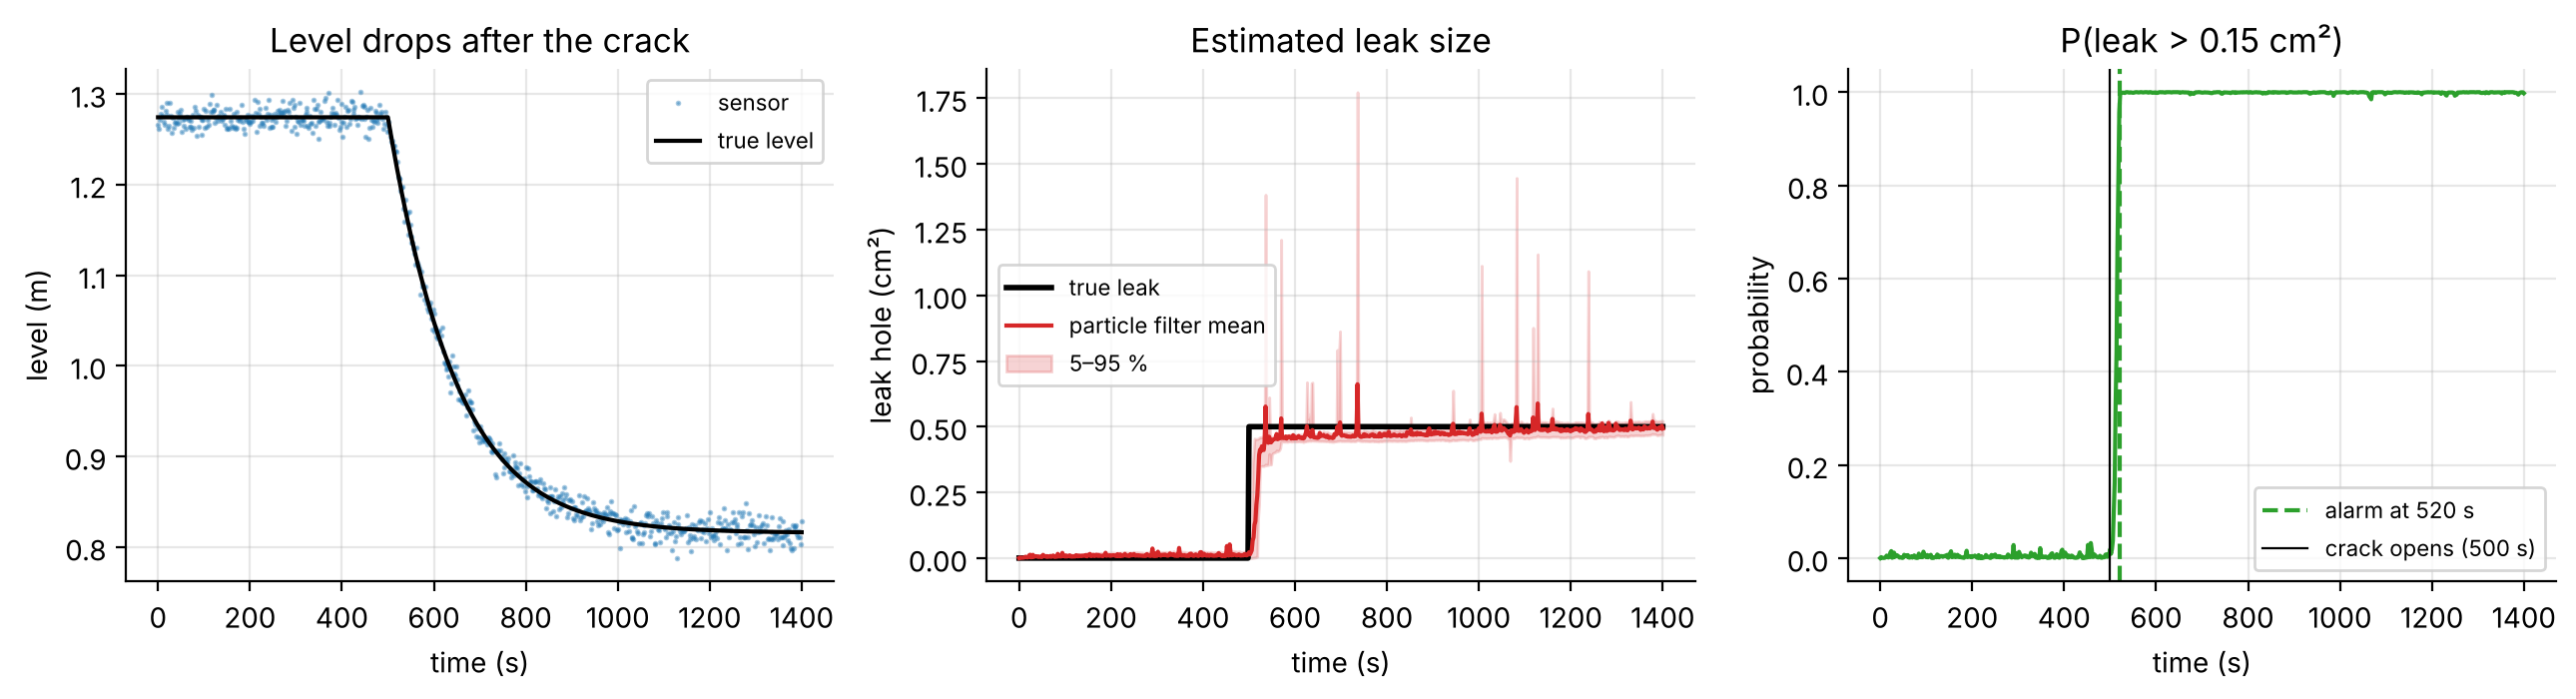

Leak alarm at 520 s, 20 s after the crack opened.
Final estimate: 0.49 cm² (true 0.50 cm²). Smallest effective sample size: 550 of 3000.


In [29]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
axs[0].plot(t_pf, y_level, ".", ms=2, alpha=0.4, label="sensor")
axs[0].plot(t_pf, h_t, c="k", lw=1.5, label="true level")
axs[0].set(xlabel="time (s)", ylabel="level (m)", title="Level drops after the crack"); axs[0].legend(fontsize=8)
axs[1].plot(t_pf, leak_true * 1e4, c="k", lw=2, label="true leak")
axs[1].plot(t_pf, leak_mean * 1e4, c="C3", label="particle filter mean")
axs[1].fill_between(t_pf, np.array(leak_lo) * 1e4, np.array(leak_hi) * 1e4, color="C3", alpha=0.2, label="5–95 %")
axs[1].set(xlabel="time (s)", ylabel="leak hole (cm²)", title="Estimated leak size"); axs[1].legend(fontsize=8)
axs[2].plot(t_pf, p_leak, c="C2")
if alarm_pf is not None:
    axs[2].axvline(alarm_pf, c="C2", ls="--", label=f"alarm at {alarm_pf:.0f} s")
axs[2].axvline(500, c="k", lw=0.8, label="crack opens (500 s)")
axs[2].set(xlabel="time (s)", ylabel="probability", title="P(leak > 0.15 cm²)"); axs[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"Leak alarm at {alarm_pf:.0f} s, {alarm_pf - 500:.0f} s after the crack opened.")
print(f"Final estimate: {leak_mean[-1]*1e4:.2f} cm² (true 0.50 cm²). Smallest effective sample size: {min(ess_log):.0f} of {n_pf}.")

The filter starts certain that there is no leak, notices that the level falls faster than the mass balance allows,
and shifts its particles to the leak sizes that explain the missing water. Its band is lopsided (it cannot go below
zero) — the kind of belief a Kalman filter cannot represent. The thin spikes in the band are particles that just
"jumped" to a random leak size: the prior keeps testing other explanations, and the measurements reject them within a step or two.

**Watch the effective sample size.** If almost all weight sits on a few particles, the cloud has collapsed and the
filter becomes overconfident. More particles, a wider disturbance model, or resampling only when the effective size
drops are the usual fixes. Exercise 8 lets you break it on purpose.

## Lesson 8 — Where this goes in current research

| Idea from this notebook | Research direction | Starting point |
|---|---|---|
| Flux form, telescoping sums (L2) | Finite-volume layers in learned PDE solvers | LeVeque, *Finite Volume Methods for Hyperbolic Problems* (2002) |
| Known invariants + learned rates (L3) | Hybrid / gray-box models, universal differential equations | Rackauckas et al., "Universal Differential Equations for Scientific ML" (2020) |
| Column-stochastic dynamics (L4–L5) | Mass-conserving recurrent networks | Hoedt et al., "MC-LSTM: Mass-Conserving LSTM" (ICML 2021) |
| Soft constraint (L6-A) | Physics-informed neural networks (PINNs) | Raissi, Perdikaris & Karniadakis, *J. Comput. Phys.* (2019) |
| Message passing with fluxes (L6-C) | Graph network simulators for fluids, sand, cloth | Sanchez-Gonzalez et al., "Learning to Simulate Complex Physics with Graph Networks" (ICML 2020) |
| Learned continuous dynamics | Neural ODEs | Chen et al., "Neural Ordinary Differential Equations" (NeurIPS 2018) |
| Same idea for energy | Hamiltonian / Lagrangian neural networks | Greydanus et al., "Hamiltonian Neural Networks" (NeurIPS 2019) |
| Budget residual as a sensor (L7) | Digital twins, model-based fault detection | Isermann, *Fault-Diagnosis Systems* (2006) |
| Randomized physics (L1b) | Domain randomization, sim-to-real transfer | Tobin et al., "Domain Randomization for Transferring Deep Neural Networks from Simulation to the Real World" (IROS 2017) |
| Monte Carlo sensitivity (L1b) | Global sensitivity analysis | Saltelli et al., *Global Sensitivity Analysis: The Primer* (2008) |
| Mass on particles (L2b) | SPH and MPM simulators for liquids and granular media | Monaghan, "Smoothed Particle Hydrodynamics", *Rep. Prog. Phys.* (2005) |
| Stochastic kinetics (L3b) | Exact stochastic simulation of reaction networks | Gillespie, *J. Phys. Chem.* (1977) |
| Particle filter (L7c) | Sequential Monte Carlo, Monte Carlo localization | Gordon, Salmond & Smith, *IEE Proc. F* (1993); Thrun, Burgard & Fox, *Probabilistic Robotics* (2005) |

**The general recipe** for building a Physical AI model of anything that moves stuff around:

1. Choose control volumes (cells, nodes, compartments, objects).
2. List the conserved quantities (mass, each species or moiety, energy, momentum, charge, inventory).
3. Write the dynamics as *fluxes between volumes* plus *sources with known stoichiometry*.
4. Learn only the flux and rate laws, with outputs that cannot break the bookkeeping (non-negative rates, donor-cell form).
5. Keep a running budget at run time; a budget that does not close is information.
6. Wrap it in Monte Carlo wherever something is uncertain or random: parameters (risk, domain randomization),
   few particles or molecules (stochastic simulation), or hidden states (particle filters).

## Exercises

| # | Task | Hint |
|---|---|---|
| 1 | **Leak detection in the tank (L1).** Add a leak $q_\text{leak} = 0.3\,C_d a\sqrt{2gh}$ starting at $t = 700$ s. Assume you know $q_\text{in}$ and measure $h$ with noise of 2 mm. Detect the leak from the budget. | Compare measured storage change with $\int \rho(q_\text{in} - q_\text{out,model})\,dt$ over a sliding window. |
| 2 | **Repair the advective form (L2).** Add the missing term $-\rho\,\partial_x u$ to `rhs_advective`. Is mass now conserved exactly, or only approximately? Why? | Exactness needs telescoping, not just the correct PDE. |
| 3 | **New reaction (L3).** Add $\text{D} \to \text{B}$. Recompute the left null space. Which invariant survives? | One column more in $S$. |
| 4 | **Noise and bias (L5).** Repeat the data-size study for noise 0.0, 0.01 and 0.1. When does the black box catch up? | With no noise the errors-in-variables bias disappears. |
| 5 | **Train option C (L6).** Port `ConservingMessagePassing` to PyTorch or JAX and fit it to the three-tank data. Compare with the projection model, including the minimum level reached. | Use a fully connected 3-node graph; train on one-step error first, then on multi-step rollouts. |
| 6 | **Tare drift (L7).** Add a slowly drifting offset to the scale as a fifth state. Can the filter still tell drift from spill? | Check observability: rank of $[H; HF; HF^2; \dots]$. |
| 7 | 🎲 **Smarter sampling (L1b).** Replace random sampling with Latin hypercube sampling (`scipy.stats.qmc.LatinHypercube`) and compare how fast P(overflow) settles. | Map uniform samples to normals with `scipy.stats.norm.ppf`. |
| 8 | 🎲 **Break the particle filter (L7c).** Use 50 particles, or set `p_jump = 0`. What happens to the leak estimate and the effective sample size? | With no jumps, how could a particle ever find the leak? |
| 9 | 🎲 **Domain randomization (L5).** Train the structured model on data from many systems with randomly scaled rates $F$, then test it on a new random system. Compare with training on one system. | Draw a scale factor per trajectory. |

## Cheat sheet

| Concept | Formula | Code idea |
|---|---|---|
| General balance | $\dot m = \dot m_\text{in} - \dot m_\text{out} + \dot m_\text{gen} - \dot m_\text{cons}$ | one ODE per control volume |
| Budget closure | $\Delta m - \int(\dot m_\text{in} - \dot m_\text{out})\,dt \approx 0$ | assert it in tests |
| Flux form | $x_i \mathrel{+}= \Delta t\,(F_{i-1/2} - F_{i+1/2})$ | compute each flux once, use it twice |
| Reactions | $\dot c = S\,r(c)$ | stoichiometry known, rates learned |
| Invariants | $w^\top S = 0 \Rightarrow w^\top c$ constant | `null_space(S.T)` |
| Compartments | $\dot x = Kx$, $\mathbf 1^\top K = 0$ | `F - diag(F.sum(0))` |
| Discrete conserving map | column-stochastic $A$ | parametrize off-diagonals $\ge 0$ |
| Hard projection | $\Delta\hat x \leftarrow \Delta\hat x - \tfrac1n(\mathbf 1^\top\Delta\hat x)\mathbf 1$ | `d - d.mean()` |
| Conserving message passing | $\text{flux}_{j\to i} = r_{ij}\,x_j$, $r_{ij}\ge0$ | `np.add.at` twice with $\pm$ |
| Unmeasured flow | state in a Kalman filter driven by the balance | spill, leak, theft, sensor drift |
| 🎲 Uncertainty propagation | sample inputs → run the balance → count outcomes | vectorize over samples |
| 🎲 Monte Carlo error | standard error $\approx \sigma/\sqrt N$; for a probability $\sqrt{p(1-p)/N}$ | 4× samples = ½ error |
| 🎲 Random-walk particles | $x \mathrel{+}= u\,\Delta t + \sqrt{2D\Delta t}\,\xi$ | mass = count × mass per particle |
| 🎲 Gillespie | wait $\sim \text{Exp}(a_0)$, fire $j$ w.p. $a_j/a_0$, $x \mathrel{+}= S_{:,j}$ | invariants exact as integers |
| 🎲 Particle filter | predict with the balance → weigh by likelihood → resample | watch the effective sample size |